# DiabetesCheck AI : dépistage du diabète expliqué (IA hybride)

Mini-projet IA Hybride (ISIS Castres, 5e année) - Sujet 1. Données : Pima Indians Diabetes (768 patientes).

**Plan :**
- **Étape 1 (parties 1 à 6)** : nettoyage des données, valeurs manquantes et modèles de référence (non hybrides)
- **Étape 2 (parties 7 à 15)** : version hybride avec des règles médicales sourcées, et comparaison avec la référence

> **Version 2 : corrections apportées au notebook initial**
> 1. Le **seuil de décision est choisi sur le train** (prédictions hors-pli), et non plus sur le test : plus de fuite vers le test.
> 2. **SMOTE et seuil bas comparés à rappel égal**, au lieu de deux points de fonctionnement différents.
> 3. **Ablation robuste** : validation croisée répétée sur les 768 patientes, avec différences appariées et intervalles de confiance.
> 4. Le remplissage KNN ne porte que sur les 8 variables de départ (les colonnes de règles sont ajoutées après).
> 5. Chargement du fichier local `diabetes.csv` s'il existe (réexécution hors ligne), sinon OpenML.
> 6. Conclusions réécrites d'après les résultats obtenus.
> 7. **Nouvelles sections** : calibration (15), cohérence sur 768 patientes et monotonie (16), cas « peu de données » (17), explication SHAP + règles (18),
>    analyse d'erreurs par brique (19), coût (20), conclusion générale (21).
> 8. R6 présentée comme **règle dérivée** (USPSTF 2021 / ADA) et non plus « construite par nous » ; phrase non sourcée sur les « 5 ans » retirée.

# Étape 1 : valeurs manquantes et modèles de référence

**Objectif :** remplir les valeurs manquantes de la bonne façon, puis comparer quelques modèles classiques (non hybrides)
pour avoir une référence. Cette référence servira à voir si la version hybride (avec les règles médicales) fait mieux.

## 1. Imports et chargement des données

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

In [2]:
from pathlib import Path
from sklearn.datasets import fetch_openml

COLS = ["Pregnancies", "Glucose", "BloodPressure", "SkinThickness", "Insulin",
        "BMI", "DiabetesPedigreeFunction", "Age", "Outcome"]

# Chargement : fichier local diabetes.csv s'il existe (réexécution hors ligne), sinon OpenML comme dans l'énoncé
if Path("diabetes.csv").exists():
    df = pd.read_csv("diabetes.csv")
else:
    df = fetch_openml("diabetes", version=1, as_frame=True).frame
    df.columns = COLS
    df["Outcome"] = (df["Outcome"] == "tested_positive").astype(int)

assert list(df.columns) == COLS and df.shape == (768, 9)
print(f"Dimensions : {df.shape}")
df.head()

Dimensions : (768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


## 2. Règle de qualité : un 0 impossible = valeur manquante

Une glycémie, une pression, un pli cutané, une insuline ou un IMC égal à 0 est impossible chez une patiente vivante :
c'est une valeur qui n'a pas été mesurée. On les remplace par `NaN`. (0 grossesse est possible donc on ne touche pas.)

In [3]:
cols_zero = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
df[cols_zero] = df[cols_zero].replace(0, np.nan)

# Pourcentage de valeurs manquantes par colonne
print((df.isna().mean() * 100).round(1))

Pregnancies                  0.0
Glucose                      0.7
BloodPressure                4.6
SkinThickness               29.6
Insulin                     48.7
BMI                          1.4
DiabetesPedigreeFunction     0.0
Age                          0.0
Outcome                      0.0
dtype: float64


Insulin (49 %) et SkinThickness (30 %) ont beaucoup de manquants. Si on supprimait les lignes incomplètes on perdrait la
moitié des patientes, donc on va les remplir.

## 3. Séparation train / test

On sépare **avant** de remplir les valeurs manquantes. Sinon le remplissage utiliserait des informations du test
(fuite d'information).

In [4]:
from sklearn.model_selection import train_test_split

X = df.drop("Outcome", axis=1)
y = df["Outcome"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Train : {X_train.shape}")
print(f"Test  : {X_test.shape}")

Train : (614, 8)
Test  : (154, 8)


## 4. Comparaison des méthodes pour remplir les valeurs manquantes

On compare 3 méthodes :
- **Médiane** : on remplace par la médiane de la colonne
- **KNN** : on prend la moyenne des 5 patientes qui ressemblent le plus (glycémie, IMC, âge...)
- **MICE** : on prédit la valeur manquante à partir des autres colonnes avec une régression
  (van Buuren & Groothuis-Oudshoorn, 2011)

On met chaque méthode dans un `Pipeline` (standardisation → remplissage → modèle). L'avantage c'est que dans la validation
croisée, le remplissage est réappris à chaque fois seulement sur la partie entraînement, donc pas de fuite.
On utilise la régression logistique pour comparer.

In [5]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import SimpleImputer, KNNImputer, IterativeImputer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score

imputers = {
    "Médiane": SimpleImputer(strategy="median"),
    "KNN": KNNImputer(n_neighbors=5),
    "MICE": IterativeImputer(max_iter=20, random_state=42),
}

results_imp = []

for name, imputer in imputers.items():
    pipe = Pipeline([
        ("scaler", StandardScaler()),   # avant KNN sinon l'insuline (centaines) écrase l'IMC dans la distance
        ("imputer", imputer),
        ("model", LogisticRegression(max_iter=1000)),
    ])
    auc = cross_val_score(pipe, X_train, y_train, cv=5, scoring="roc_auc")
    results_imp.append({"Méthode": name, "AUC moyenne": auc.mean(), "Écart-type": auc.std()})

df_imp = pd.DataFrame(results_imp).round(3)
df_imp

,Méthode,AUC moyenne,Écart-type
0,Médiane,0.843,0.029
1,KNN,0.842,0.029
2,MICE,0.843,0.030


**Résultat :** les 3 méthodes donnent presque la même AUC (écart de l'ordre de 0.001), alors que l'écart-type est d'environ
0.03. Donc aucune n'est vraiment meilleure. On garde **KNN** car il utilise les autres mesures de la patiente pour remplir.

### Et si on remplissait selon que la patiente est malade ou pas ?

Idée : pour une malade, on met une valeur au hasard dans l'intervalle habituel des malades (Q1-Q3), et pareil pour les
non malades. Le problème c'est que pour une nouvelle patiente **on ne sait pas si elle est malade** (c'est ce qu'on veut
prédire). On teste quand même pour voir ce qui se passe.

In [6]:
# Intervalles Q1-Q3 de chaque colonne, pour les non malades (0) et les malades (1), calculés sur le train
train = X_train.copy()
train["Outcome"] = y_train
q1 = train.groupby("Outcome")[cols_zero].quantile(0.25)
q3 = train.groupby("Outcome")[cols_zero].quantile(0.75)
print("Q1 :\n", q1, "\n\nQ3 :\n", q3)

Q1 :
          Glucose  BloodPressure  SkinThickness  Insulin    BMI
Outcome                                                       
0           94.0           62.0           19.0     64.0  25.90
1          119.0           68.0           27.0    130.0  31.05 

Q3 :
          Glucose  BloodPressure  SkinThickness  Insulin   BMI
Outcome                                                      
0          124.0           78.0           33.0    158.0  35.1
1          168.0           83.0           39.0    231.0  39.1


In [7]:
from sklearn.metrics import roc_auc_score

np.random.seed(42)

# Remplissage selon la classe : on tire une valeur au hasard entre Q1 et Q3 de la classe de la patiente
def remplir_par_classe(X_part, y_part):
    X_part = X_part.copy()
    for col in cols_zero:
        for classe in [0, 1]:
            manque = X_part[col].isna() & (y_part == classe)
            X_part.loc[manque, col] = np.random.uniform(q1.loc[classe, col], q3.loc[classe, col], manque.sum())
    return X_part

X_train_classe = remplir_par_classe(X_train, y_train)

# Cas 1 (triche) : on remplit aussi le test avec sa vraie réponse
X_test_triche = remplir_par_classe(X_test, y_test)

# Cas 2 (honnête) : on ne connaît pas la réponse du test, donc on le remplit avec la médiane du train
X_test_honnete = X_test.fillna(X_train.median())

scaler = StandardScaler().fit(X_train_classe)
model = LogisticRegression(max_iter=1000).fit(scaler.transform(X_train_classe), y_train)

auc_triche = roc_auc_score(y_test, model.predict_proba(scaler.transform(X_test_triche))[:, 1])
auc_honnete = roc_auc_score(y_test, model.predict_proba(scaler.transform(X_test_honnete))[:, 1])

print(f"AUC test - remplissage par classe (triche)  : {auc_triche:.3f}")
print(f"AUC test - remplissage par classe (honnête) : {auc_honnete:.3f}")

AUC test - remplissage par classe (triche)  : 0.832
AUC test - remplissage par classe (honnête) : 0.788


**Conclusion :** la version triche a l'air meilleure (environ 0.83), mais c'est faux : le modèle a appris que « une
insuline remplie avec une valeur de malade = malade ». On a écrit la réponse dans les données. Dans la version honnête
(la seule possible en vrai), le score retombe vers 0.79, c'est même moins bien que KNN. Donc on **n'utilise pas** cette
méthode : c'est une fuite d'information.

## 5. Comparaison des modèles de référence

On garde 3 modèles :
- **Régression logistique** (demandée dans l'énoncé, simple et explicable)
- **Random Forest**
- **XGBoost** (gradient boosting, demandé dans l'énoncé)

Pour chaque modèle : validation croisée sur le train (AUC) puis évaluation sur le test.

In [8]:
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import f1_score, recall_score, accuracy_score

models = {
    "Régression logistique": LogisticRegression(max_iter=1000),
    "Random Forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=3, random_state=42),
    "XGBoost": XGBClassifier(n_estimators=300, max_depth=3, learning_rate=0.05, random_state=42),
}

results = []

for name, model in models.items():
    pipe = Pipeline([
        ("scaler", StandardScaler()),
        ("imputer", KNNImputer(n_neighbors=5)),
        ("model", model),
    ])

    # Validation croisée sur le train
    auc_cv = cross_val_score(pipe, X_train, y_train, cv=5, scoring="roc_auc").mean()

    # Entraînement sur tout le train et prédiction sur le test
    pipe.fit(X_train, y_train)
    y_proba = pipe.predict_proba(X_test)[:, 1]
    y_pred = pipe.predict(X_test)

    results.append({
        "Modèle": name,
        "AUC (CV)": auc_cv,
        "AUC (test)": roc_auc_score(y_test, y_proba),
        "F1": f1_score(y_test, y_pred),
        "Rappel": recall_score(y_test, y_pred),
        "Accuracy": accuracy_score(y_test, y_pred),
    })

df_results = pd.DataFrame(results).round(3)
df_results

,Modèle,AUC (CV),AUC (test),F1,Rappel,Accuracy
0,Régression logistique,0.842,0.814,0.531,0.481,0.701
1,Random Forest,0.836,0.812,0.588,0.556,0.727
2,XGBoost,0.819,0.832,0.692,0.685,0.786


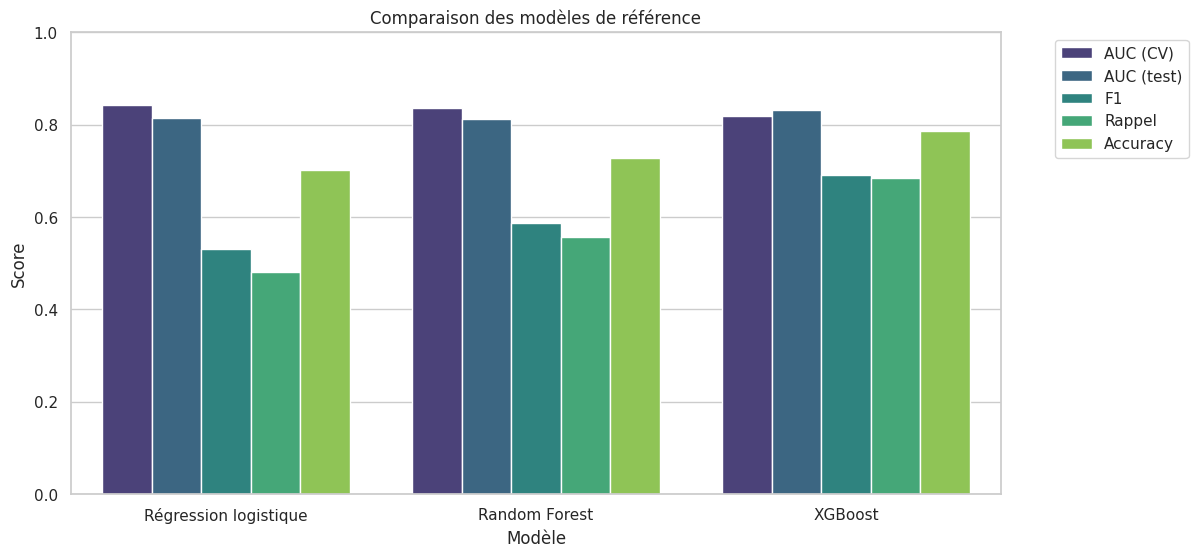

In [9]:
df_plot = df_results.melt(id_vars="Modèle", var_name="Métrique", value_name="Score")

plt.figure(figsize=(12, 6))
sns.barplot(x="Modèle", y="Score", hue="Métrique", data=df_plot, palette="viridis")
plt.title("Comparaison des modèles de référence")
plt.ylim(0, 1)
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.show()

### Ce qu'on conclut de cette comparaison

**Rappel des métriques :**
- **AUC** : capacité à mettre les malades au-dessus des non malades (1 = parfait, 0.5 = hasard)
- **Rappel** : sur 10 malades, combien on en détecte (le plus important pour un dépistage)
- **F1** : compromis entre rappel et précision (éviter les fausses alertes)

| Modèle | AUC (CV) | AUC (test) | Rappel (test) |
|---|---|---|---|
| Régression logistique | **0.842** | 0.814 | 0.48 |
| Random Forest | 0.836 | 0.812 | 0.56 |
| XGBoost | 0.819 | **0.832** | **0.69** |

**1. En validation croisée, la régression logistique est la meilleure.** La validation croisée est la mesure la plus
fiable car elle teste le modèle 5 fois sur des patientes différentes (614 patientes au total).

**2. Sur le test, c'est XGBoost qui est le meilleur.** Le classement s'inverse ! Ça vient du fait que le test ne contient
que 154 patientes : quelques patientes en plus ou en moins bien classées suffisent à changer l'ordre. Les écarts d'AUC
(0.02 environ) sont plus petits que l'incertitude (environ ± 0.03), donc **les 3 modèles sont en réalité au même niveau**.

**3. Le rappel est faible pour tous les modèles (entre 48 % et 69 %).** Ça veut dire qu'on rate entre 3 et 5 malades sur 10.
C'est parce qu'on utilise le seuil par défaut de 0.5 : une patiente est classée malade seulement si le risque dépasse 50 %.
Pour un dépistage, on pourra **baisser ce seuil** plus tard (le seuil sera choisi sur le train, voir plus bas) pour détecter plus de malades.

**Choix :** comme les modèles sont au même niveau, on garde les 2 modèles demandés par l'énoncé comme **références** :
- la **régression logistique** : la meilleure en validation croisée et la plus facile à expliquer à un médecin
- **XGBoost** : le meilleur sur le test et le meilleur rappel

Random Forest n'apporte rien de plus, on ne le garde pas pour la suite.

### Choix du seuil et SMOTE : sur le train uniquement

En dépistage, rater une malade (faux négatif) est plus grave qu'envoyer chez le médecin quelqu'un qui n'est pas malade
(faux positif). On veut un bon **rappel**. Deux leviers : **SMOTE** (rééquilibrer les classes) ou **baisser le seuil** de décision.

**Correction par rapport à la première version :** le seuil ne doit pas être choisi en regardant le test (sinon les
résultats du test sont optimistes). On le choisit donc avec des prédictions **hors-pli** obtenues par validation croisée
sur le train : chaque patiente du train est prédite par un modèle qui ne l'a pas vue.

**Critère (choix clinique, modifiable) :** le plus grand seuil qui atteint un rappel d'au moins 80 % sur le train hors-pli.

**Comparaison équitable :** SMOTE et seuil bas déplacent tous deux le point de fonctionnement. Pour les comparer on les met
au **même rappel** (80 %) et on regarde le taux de fausses alertes et la calibration (Brier).

In [10]:
from sklearn.model_selection import cross_val_predict, StratifiedKFold
from sklearn.metrics import confusion_matrix, brier_score_loss
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
RAPPEL_CIBLE = 0.80
y_tr = y_train.to_numpy()


def pipe_modele(nom, smote=False):
    modele = (LogisticRegression(max_iter=1000) if nom == "Régression logistique"
              else XGBClassifier(n_estimators=300, max_depth=3, learning_rate=0.05, random_state=42))
    etapes = [("scaler", StandardScaler()), ("imputer", KNNImputer(n_neighbors=5))]
    if smote:
        etapes.append(("smote", SMOTE(random_state=42)))   # appliqué seulement sur la partie entraînement de chaque pli
    return (ImbPipeline if smote else Pipeline)(etapes + [("model", modele)])


def seuil_pour_rappel(y_vrai, proba, cible=RAPPEL_CIBLE):
    # plus grand seuil dont le rappel atteint la cible
    for s in np.sort(np.unique(proba))[::-1]:
        if (proba[y_vrai == 1] >= s).mean() >= cible:
            return float(s)
    return 0.0


# Prédictions hors-pli sur le train (aucune patiente n'est prédite par un modèle qui l'a vue)
oof = {}
for nom, sm in [("Régression logistique", False), ("XGBoost", False), ("XGBoost", True)]:
    oof[(nom, sm)] = cross_val_predict(pipe_modele(nom, sm), X_train, y_train, cv=skf, method="predict_proba")[:, 1]

lignes = []
for (nom, sm), p in oof.items():
    s = seuil_pour_rappel(y_tr, p)
    pred = p >= s
    lignes.append({"Version": nom + (" + SMOTE" if sm else ""), "Seuil pour rappel 80 %": round(s, 3),
                   "Rappel (train hors-pli)": round(recall_score(y_tr, pred), 3),
                   "Fausses alertes (% des non-malades)": round(100 * pred[y_tr == 0].mean(), 1),
                   "Brier": round(brier_score_loss(y_tr, p), 3)})
display(pd.DataFrame(lignes).set_index("Version"))

# Rappel / fausses alertes pour quelques seuils fixes, XGBoost sans SMOTE
p = oof[("XGBoost", False)]
display(pd.DataFrame([{"Seuil": s, "Rappel": round(recall_score(y_tr, p >= s), 3),
                       "Fausses alertes (%)": round(100 * (p >= s)[y_tr == 0].mean(), 1)} for s in [0.5, 0.4, 0.3]]).set_index("Seuil"))

# Seuils retenus (choisis sur le train uniquement), un par modèle
SEUILS = {"Régression logistique": seuil_pour_rappel(y_tr, oof[("Régression logistique", False)]),
          "XGBoost": seuil_pour_rappel(y_tr, oof[("XGBoost", False)])}
print("Seuils retenus :", {k: round(v, 3) for k, v in SEUILS.items()})

,Seuil pour rappel 80 %,Rappel (train hors-pli),Fausses alertes (% des non-malades),Brier
Version,,,,
Régression logistique,0.291,0.804,29.5,0.150
XGBoost,0.236,0.804,32.0,0.176
XGBoost + SMOTE,0.324,0.804,30.5,0.176


,Rappel,Fausses alertes (%)
Seuil,,
0.5,0.598,18.2
0.4,0.668,24.0
0.3,0.762,28.5


Seuils retenus : {'Régression logistique': 0.291, 'XGBoost': 0.236}


**Résultats (train hors-pli) :**
- Le seuil qui donne 80 % de rappel est **0.29** pour la régression logistique et **0.24** pour XGBoost. Pour XGBoost
  il est plus bas que le 0.3 de la première version : ses probabilités sont plus « tassées » (son Brier hors-pli est de 0.176,
  contre 0.150 pour la régression logistique).
- **À rappel égal, SMOTE ne fait pas mieux que baisser le seuil** : 30.5 % de fausses alertes avec SMOTE contre 32.0 % sans
  (environ 6 patientes sur les 400 non-malades du train), et le même Brier (0.176). La conclusion de la première version
  (« 0.3 fait mieux que SMOTE ») comparait SMOTE à 0.5 avec un seuil bas, donc deux rappels différents ; et l'écart de Brier
  observé sur le test (0.172 contre 0.164) disparaît en validation croisée.
- On **n'utilise donc pas SMOTE** : à performance équivalente, baisser le seuil est plus simple, ne crée pas de patientes
  fictives et ne dépend pas d'un tirage aléatoire.

**Évaluation unique sur le test**, avec les seuils choisis ci-dessus (on ne retouche plus rien après avoir regardé le test).
L'intervalle de confiance du rappel est celui de Wilson : avec 54 malades dans le test, il est large.

In [11]:
def wilson(k, n, z=1.96):
    p = k / n
    d = 1 + z * z / n
    c = p + z * z / (2 * n)
    h = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n))
    return (c - h) / d, (c + h) / d

lignes = []
for nom in SEUILS:
    p_test = pipe_modele(nom).fit(X_train, y_train).predict_proba(X_test)[:, 1]
    for s in [0.5, SEUILS[nom]]:
        tn, fp, fn, tp = confusion_matrix(y_test, p_test >= s).ravel()
        lo, hi = wilson(tp, tp + fn)
        lignes.append({"Modèle": nom, "Seuil": round(s, 3), "Rappel": round(tp / (tp + fn), 3),
                       "IC95% rappel": f"[{lo:.2f} ; {hi:.2f}]", "Malades ratées (FN)": fn, "Fausses alertes (FP)": fp})
pd.DataFrame(lignes).set_index(["Modèle", "Seuil"])

Rappel   IC95% rappel  Malades ratées (FN)  \
Modèle                Seuil                                               
Régression logistique 0.500   0.481  [0.35 ; 0.61]                   28   
                      0.291   0.796  [0.67 ; 0.88]                   11   
XGBoost               0.500   0.685  [0.55 ; 0.79]                   17   
                      0.236   0.889  [0.78 ; 0.95]                    6   

                             Fausses alertes (FP)  
Modèle                Seuil                        
Régression logistique 0.500                    18  
                      0.291                    31  
XGBoost               0.500                    16  
                      0.236                    32

**Lecture :** au seuil choisi sur le train, le rappel sur le test est de 0.80 [0.67 ; 0.88] pour la régression logistique
(la cible était 0.80) et de 0.89 [0.78 ; 0.95] pour XGBoost. Ce dernier chiffre est plutôt favorable : avec 54 malades,
l'intervalle est large, et c'est bien **0.80** qu'il faut attendre en moyenne. Le coût est d'environ 31 à 32 fausses alertes
pour 100 non-malades (contre 16 à 18 au seuil 0.5). Sur le test, passer du seuil 0.5 au seuil choisi fait gagner 11 malades à
XGBoost (17 ratées → 6) et 17 à la régression logistique (28 → 11).

### Performance par tranche d'âge

Le jeu contient **uniquement des femmes Pima de 21 ans et plus** : on ne peut donc pas comparer hommes et femmes.
Par contre on peut regarder si le jeu est déséquilibré selon l'âge, et si le modèle marche aussi bien pour toutes les tranches d'âge.

In [12]:
# On découpe l'âge en 3 tranches
tranches = pd.cut(X_test["Age"], bins=[20, 30, 45, 100], labels=["21-30 ans", "31-45 ans", "46 ans et +"])

# On réentraîne XGBoost (sans SMOTE) pour avoir ses probabilités sur le test
pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("imputer", KNNImputer(n_neighbors=5)),
    ("model", XGBClassifier(n_estimators=300, max_depth=3, learning_rate=0.05, random_state=42)),
])
pipe.fit(X_train, y_train)
proba = pipe.predict_proba(X_test)[:, 1]
pred = (proba >= 0.5).astype(int)

results_age = []

for tranche in tranches.cat.categories:
    masque = (tranches == tranche).values
    results_age.append({
        "Tranche d'âge": tranche,
        "Nb patientes": masque.sum(),
        "% de malades": y_test[masque].mean() * 100,
        "AUC": roc_auc_score(y_test[masque], proba[masque]),
        "Rappel": recall_score(y_test[masque], pred[masque]),
    })

pd.DataFrame(results_age).round(2)

,Tranche d'âge,Nb patientes,% de malades,AUC,Rappel
0,21-30 ans,89,20.22,0.77,0.44
1,31-45 ans,40,65.00,0.76,0.77
2,46 ans et +,25,40.00,0.85,0.90


**Conclusion :**
- Le jeu est déséquilibré selon l'âge : 58 % des patientes du test ont entre 21 et 30 ans, et seulement 20 % d'entre elles
  sont malades (contre 65 % chez les 31-45 ans).
- Le modèle détecte mal les jeunes malades : rappel de **0.44** chez les 21-30 ans (8 malades détectées sur 18), contre
  0.77 et 0.90 pour les tranches plus âgées. Le modèle a appris que « jeune = rarement malade » et sous-estime leur risque.
  C'est un **biais selon l'âge**.
- Les tranches sont petites (25 patientes chez les 46 ans et +), donc ces chiffres sont à prendre avec prudence.
- Piste : les règles médicales (ex : glycémie ≥ 140) ne dépendent pas de l'âge et pourraient aider à repérer ces jeunes
  malades. On le vérifiera à l'étape 2.
- Rappel : le jeu ne contient que des **femmes Pima de 21 ans et plus**, on ne peut pas généraliser ces résultats à
  d'autres populations (hommes, autres origines, moins de 21 ans).

### Quelles variables comptent le plus ? (coefficients de la régression logistique)

Chaque variable a un coefficient : positif = augmente le risque, négatif = le diminue. Comme les données sont
standardisées, on peut comparer les coefficients entre eux : plus il est grand, plus la variable compte.

/tmp/ipykernel_213/3688249487.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x="Coefficient", y="Variable", data=coefs, palette="coolwarm")


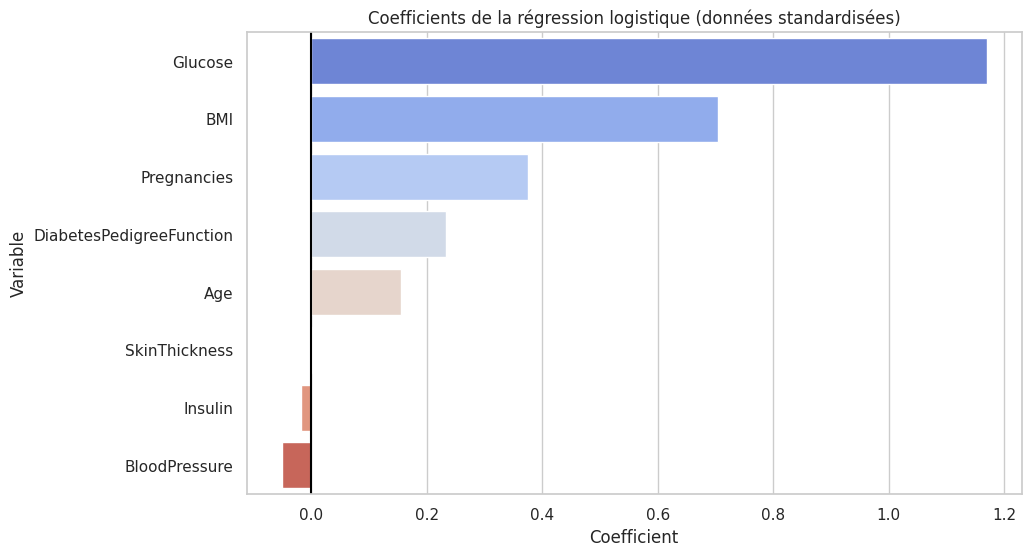

,Variable,Coefficient
1,Glucose,1.169
5,BMI,0.704
0,Pregnancies,0.376
6,DiabetesPedigreeFunction,0.233
7,Age,0.156
3,SkinThickness,0.001
4,Insulin,-0.019
2,BloodPressure,-0.051


In [13]:
# On entraîne la régression logistique sur tout le train
pipe_lr = Pipeline([
    ("scaler", StandardScaler()),
    ("imputer", KNNImputer(n_neighbors=5)),
    ("model", LogisticRegression(max_iter=1000)),
])
pipe_lr.fit(X_train, y_train)

# On récupère les coefficients du modèle
coefs = pd.DataFrame({
    "Variable": X_train.columns,
    "Coefficient": pipe_lr.named_steps["model"].coef_[0],
}).sort_values(by="Coefficient", ascending=False)

# Visualisation
plt.figure(figsize=(10, 6))
sns.barplot(x="Coefficient", y="Variable", data=coefs, palette="coolwarm")
plt.title("Coefficients de la régression logistique (données standardisées)")
plt.axvline(0, color="black")
plt.show()

coefs.round(3)

**Conclusion :**
- **Glucose** (1.17) et **BMI** (0.70) sont de loin les variables les plus importantes : +30 mg/dL de glycémie multiplie
  la cote de risque par 3.2, et +7 kg/m² d'IMC la multiplie par 2. C'est cohérent avec la médecine.
- **Insulin, SkinThickness et BloodPressure** ont un coefficient proche de 0 : le modèle ne les utilise presque pas.
  Ça explique pourquoi la méthode de remplissage des valeurs manquantes ne changeait rien (ce sont justement les
  variables qui manquent le plus).
- **Age** compte peu (0.16), sûrement parce qu'il est lié au nombre de grossesses, qui « prend » une partie de son effet.
- Les variables importantes pour le modèle sont les mêmes que celles des règles médicales (glycémie, IMC) : le modèle
  et les recommandations sont d'accord.

### Matrice de confusion : seuil 0.5 vs seuil choisi sur le train

On regarde concrètement combien de malades sont ratées (faux négatifs) et combien de fausses alertes on donne
(faux positifs), avec le seuil par défaut (0.5) et avec le seuil choisi sur le train pour XGBoost (rappel cible 80 %).

Seuil 0.50 : 37 malades détectées sur 54, 17 ratées, 16 fausses alertes
Seuil 0.24 : 48 malades détectées sur 54, 6 ratées, 32 fausses alertes


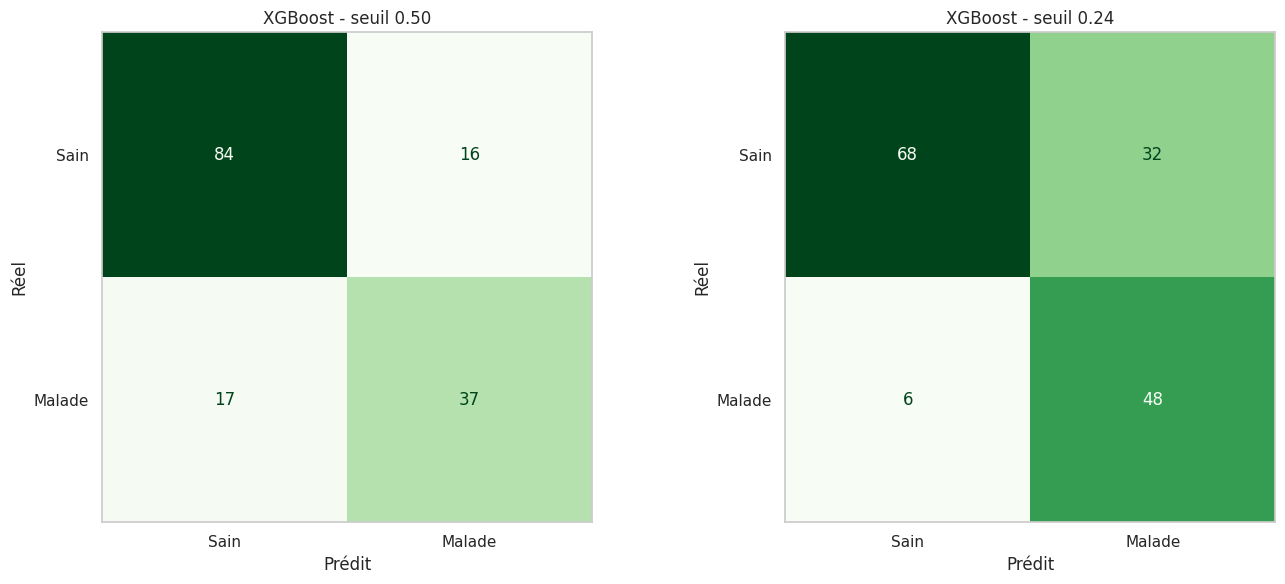

In [14]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# On utilise les probabilités de XGBoost calculées dans la partie "Performance par tranche d'âge" (variable proba)
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for ax, seuil in zip(axes, [0.5, SEUILS["XGBoost"]]):
    y_pred_seuil = (proba >= seuil).astype(int)
    cm = confusion_matrix(y_test, y_pred_seuil)

    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Sain", "Malade"])
    disp.plot(cmap="Greens", values_format="d", ax=ax, colorbar=False)
    ax.set_title(f"XGBoost - seuil {seuil:.2f}")
    ax.set_xlabel("Prédit")
    ax.set_ylabel("Réel")
    ax.grid(False)

    tn, fp, fn, tp = cm.ravel()
    print(f"Seuil {seuil:.2f} : {tp} malades détectées sur {tp + fn}, {fn} ratées, {fp} fausses alertes")

plt.tight_layout()
plt.show()

**Conclusion :**
- Avec le seuil **0.5** : on détecte 37 malades sur 54, on en **rate 17** (presque 1 sur 3), et on donne 16 fausses alertes.
- Avec le seuil **0.24** (choisi sur le train) : on détecte 48 malades sur 54, on en **rate 6**, mais on donne 32 fausses alertes.
- On récupère **11 malades** en échange de **16 fausses alertes** en plus. Pour un dépistage c'est un bon échange : une fausse
  alerte = un rendez-vous chez le médecin en plus, alors qu'une malade ratée = un diabète non soigné.
- Pour la suite on utilise **un seuil par modèle**, choisi sur le train (régression logistique 0.29, XGBoost 0.24), et on ne
  le retouche plus après avoir regardé le test.

## 6. Conclusion de l'étape 1

- **Valeurs manquantes :** médiane, KNN et MICE donnent le même résultat (AUC ≈ 0.84). On garde KNN. Le remplissage
  selon la classe (malade / pas malade) est une fuite d'information, on ne l'utilise pas.
- **Modèles :** les 3 modèles ont des AUC proches (0.81-0.84) : ils sont au même niveau. On garde la
  **régression logistique** (la plus explicable) et **XGBoost** comme références.
- **Seuil et SMOTE :** le seuil est choisi **sur le train hors-pli** (rappel cible 80 %) : 0.29 pour la régression logistique,
  0.24 pour XGBoost. À rappel égal, SMOTE n'apporte rien de plus qu'un seuil bas : on ne l'utilise pas.
- **Effet du seuil sur le test :** XGBoost passe de 17 à 6 malades ratées, pour 16 fausses alertes en plus.
- **Âge :** au seuil 0.5, le modèle rate plus d'une jeune malade sur deux (rappel 0.44 chez les 21-30 ans) : biais à étudier
  dans la version hybride.
- **Variables importantes :** glycémie et IMC dominent, insuline / pli cutané / pression ne servent presque pas.
- **Limite :** le jeu ne contient que des femmes Pima de 21 ans et plus, on ne peut pas généraliser à d'autres populations.
- **Prochaine étape :** ajouter les **règles médicales** (version hybride) et comparer avec ces résultats.

# Étape 2 : version hybride avec des règles médicales

**Objectif :** ajouter des connaissances médicales au modèle, de 2 façons :
1. **Règles en entrée** : on crée de nouvelles colonnes à partir de seuils médicaux (ex : « obèse = IMC ≥ 30 »)
2. **Règles en sortie** : après la prédiction du modèle, des règles peuvent corriger la décision, en indiquant leur source

On réutilise les données de l'étape 1 (`X_train`, `X_test`, même découpage), donc pas besoin de les recharger.
Comme décidé à l'étape 1, on utilise les **seuils de décision choisis sur le train** à l'étape 1 (un par modèle, rappel cible de 80 %).

## 7. Les règles médicales et leurs sources

**Attention aux unités :** dans le jeu Pima, `Glucose` est la glycémie **2 h après une charge de 75 g de glucose** (HGPO),
en mg/dL. Les seuils de l'ADA pour l'HGPO s'appliquent donc directement (ce ne sont pas les seuils à jeun : 100 / 126).

| Règle | Condition | Signification | Source |
|---|---|---|---|
| R1 | Glucose ≥ 200 | diabète | ADA, *Standards of Care in Diabetes 2024*, section 2 |
| R2 | 140 ≤ Glucose < 200 | intolérance au glucose (prédiabète) | ADA 2024 section 2 ; OMS 2006 |
| R3 | BMI ≥ 30 | obésité | OMS, classification de l'IMC |
| R4 | BMI ≥ 25 et Age ≥ 35 | dépistage recommandé (surpoids + âge ; l'USPSTF vise 35-70 ans) | USPSTF 2021, *Screening for Prediabetes and Type 2 Diabetes*, JAMA 2021;326(8):736-743 |
| R5 | BloodPressure ≥ 90 | hypertension (pression diastolique) | ESC/ESH 2018 ; facteur de risque listé par l'ADA |
| R6 | Glucose < 140 et BMI < 25 et Age < 35 | aucun critère de dépistage rempli → risque faible | **règle dérivée** de USPSTF 2021 et ADA (voir ci-dessous) |

**R6 est une règle dérivée, pas une recommandation officielle.** Elle regroupe les patientes qui ne remplissent **aucun critère
de dépistage** : moins de 35 ans (l'USPSTF 2021 recommande le dépistage à partir de 35 ans chez les adultes en surpoids ou obèses,
l'ADA à partir de 35 ans pour tous), IMC < 25 (pas de surpoids, OMS) et glycémie à 2 h < 140 mg/dL (pas d'intolérance au glucose, ADA).
Deux limites à garder en tête :
- « ne pas être dans les critères de dépistage » ne veut pas dire « risque nul » : le plafond de 0.1 est fixé **empiriquement**
  (1 diabétique sur 59 dans le train), pas par une recommandation ;
- c'est la seule règle qui **abaisse** un risque : elle peut transformer une alerte en non-alerte (fausse rassurance). Ses effets
  sont mesurés aux sections « Cohérence » et « Analyse d'erreurs ».

On regarde d'abord combien de patientes sont concernées par chaque règle, et leur taux de diabète.

In [15]:
def ajouter_regles(X):
    X = X.copy()
    # Une valeur manquante (NaN) donne False dans les comparaisons : la règle ne se déclenche pas
    X["R1_diabete"] = (X["Glucose"] >= 200).astype(int)
    X["R2_intolerance"] = ((X["Glucose"] >= 140) & (X["Glucose"] < 200)).astype(int)
    X["R3_obesite"] = (X["BMI"] >= 30).astype(int)
    X["R4_depistage"] = ((X["BMI"] >= 25) & (X["Age"] >= 35)).astype(int)
    X["R5_hypertension"] = (X["BloodPressure"] >= 90).astype(int)
    X["R6_faible_risque"] = ((X["Glucose"] < 140) & (X["BMI"] < 25) & (X["Age"] < 35)).astype(int)
    return X

regles = ["R1_diabete", "R2_intolerance", "R3_obesite", "R4_depistage", "R5_hypertension", "R6_faible_risque"]

# Statistiques sur le train uniquement
train_regles = ajouter_regles(X_train)
stats = []

for r in regles:
    active = train_regles[r] == 1

    # Si la règle ne se déclenche jamais, on ne peut pas calculer de taux
    if active.sum() > 0:
        taux_si_vraie = y_train[active].mean()
    else:
        taux_si_vraie = np.nan

    stats.append({
        "Règle": r,
        "Nb patientes": active.sum(),
        "Taux diabète si règle vraie": taux_si_vraie,
        "Taux diabète sinon": y_train[~active].mean(),
    })

df_stats = pd.DataFrame(stats).round(2)
df_stats

,Règle,Nb patientes,Taux diabète si règle vraie,Taux diabète sinon
0,R1_diabete,0,NaN,0.35
1,R2_intolerance,156,0.71,0.23
2,R3_obesite,379,0.46,0.17
3,R4_depistage,202,0.54,0.25
4,R5_hypertension,44,0.50,0.34
5,R6_faible_risque,59,0.02,0.38


**Observations :**
- **R1 ne se déclenche jamais** : dans le jeu Pima la glycémie maximum est 199. D'après la description du jeu (OpenML/UCI), l'étiquette « diabète » est définie par les critères de l'OMS
  (glycémie à 2 h ≥ 200 mg/dL) : le jeu semble donc plafonné sous ce seuil. On garde quand même la
  règle : elle servira pour les cas hors distribution (une nouvelle patiente avec une glycémie de 250).
- **R2 (intolérance au glucose)** : environ 2/3 des patientes concernées sont diabétiques, contre environ 1/4 sinon.
- **R6 (aucun facteur de risque)** : presque aucune patiente concernée n'est diabétique, c'est une règle très fiable.
- **R5 (hypertension)** : peu de patientes (44) et peu de différence (50 % contre 34 %) : c'est la
  règle la plus faible. C'est cohérent avec l'étape 1, où la pression avait un coefficient proche de 0.

## 8. Référence (rappel de l'étape 1)

On recalcule les 2 modèles de référence (régression logistique et XGBoost, **sans règles**), cette fois avec les
**seuils choisis sur le train** à l'étape 1 (0.29 et 0.24). C'est à ces résultats qu'on comparera les versions hybrides.

Pour ne pas réécrire les mêmes lignes à chaque fois, on crée 2 petites fonctions :
- `creer_pipeline` : standardisation → remplissage KNN → modèle (comme à l'étape 1). Quand on ajoute les colonnes de règles,
  elles sont ajoutées **après** le remplissage KNN, pour ne pas modifier les distances qui servent à remplir les valeurs
  manquantes (sinon l'ablation mélangerait deux effets).
- `evaluer` : calcule l'AUC, le F1, le rappel et l'accuracy avec le seuil du modèle.

In [16]:
from sklearn.compose import ColumnTransformer

BASE_COLS = list(X_train.columns)   # les 8 variables de départ
REGLES_COLS = regles                # les 6 colonnes de règles


def creer_pipeline(model, avec_regles=False):
    # Le remplissage KNN ne porte que sur les 8 variables de départ : les colonnes de règles (0/1)
    # sont ajoutées après, pour ne pas modifier les distances utilisées pour remplir les valeurs manquantes.
    base = Pipeline([("scaler", StandardScaler()), ("imputer", KNNImputer(n_neighbors=5))])
    blocs = [("base", base, BASE_COLS)]
    if avec_regles:
        blocs.append(("regles", "passthrough", REGLES_COLS))
    return Pipeline([("pre", ColumnTransformer(blocs)), ("model", model)])


def evaluer(modele, version, y_vrai, y_proba, seuil=None):
    # Par défaut on utilise le seuil choisi sur le train pour ce modèle (dictionnaire SEUILS)
    if seuil is None:
        seuil = SEUILS[modele]
    y_pred = (y_proba >= seuil).astype(int)
    return {
        "Modèle": modele,
        "Version": version,
        "AUC": roc_auc_score(y_vrai, y_proba),
        "F1": f1_score(y_vrai, y_pred),
        "Rappel": recall_score(y_vrai, y_pred),
        "Accuracy": accuracy_score(y_vrai, y_pred),
    }


models = {
    "Régression logistique": LogisticRegression(max_iter=1000),
    "XGBoost": XGBClassifier(n_estimators=300, max_depth=3, learning_rate=0.05, random_state=42),
}

proba_ref = {}
results = []

for name, model in models.items():
    pipe = creer_pipeline(model)
    pipe.fit(X_train, y_train)
    proba_ref[name] = pipe.predict_proba(X_test)[:, 1]
    results.append(evaluer(name, "1. Référence", y_test, proba_ref[name]))

pd.DataFrame(results).round(3)

,Modèle,Version,AUC,F1,Rappel,Accuracy
0,Régression logistique,1. Référence,0.814,0.672,0.796,0.727
1,XGBoost,1. Référence,0.832,0.716,0.889,0.753


**Conclusion :** l'AUC ne change pas par rapport à l'étape 1 (0.814 et 0.832), c'est normal car l'AUC ne dépend pas
du seuil. Par contre le **rappel monte beaucoup** grâce au seuil choisi sur le train : 0.48 → 0.80 pour la régression
logistique et 0.69 → 0.89 pour XGBoost. C'est notre référence pour la suite.

## 9. Hybride n°1 : règles en entrée

On ajoute les colonnes des règles aux 8 variables de départ. Le modèle peut alors utiliser directement des seuils médicaux.

In [17]:
X_train_r = ajouter_regles(X_train)
X_test_r = ajouter_regles(X_test)

proba_entree = {}

for name, model in models.items():
    pipe = creer_pipeline(model, avec_regles=True)
    pipe.fit(X_train_r, y_train)
    proba_entree[name] = pipe.predict_proba(X_test_r)[:, 1]
    results.append(evaluer(name, "2. Règles en entrée", y_test, proba_entree[name]))

pd.DataFrame(results).round(3)

,Modèle,Version,AUC,F1,Rappel,Accuracy
0,Régression logistique,1. Référence,0.814,0.672,0.796,0.727
1,XGBoost,1. Référence,0.832,0.716,0.889,0.753
2,Régression logistique,2. Règles en entrée,0.821,0.692,0.852,0.734
3,XGBoost,2. Règles en entrée,0.829,0.701,0.870,0.740


**Conclusion (sur le test uniquement, 154 patientes) :**
- **Régression logistique** : AUC 0.814 → 0.821, rappel 0.80 → 0.85 (3 malades détectées en plus sur 54).
- **XGBoost** : AUC 0.832 → 0.829, rappel 0.89 → 0.87 (1 malade de moins).
- Les écarts sont de 1 à 3 patientes et de ± 0.01 d'AUC, de signe opposé selon le modèle : **à ce stade on ne peut rien en
  conclure**, la section « Ablation robuste » ci-dessous tranche. Une hypothèse plausible est que les règles donnent des
  « marches » à la régression logistique (relation linéaire) alors que les arbres trouvent déjà ces seuils ; elle reste à
  démontrer.

## 10. Hybride n°2 : règles en sortie

Après la prédiction du modèle, on applique 2 règles qui **corrigent** la probabilité :
- **R1** (Glucose ≥ 200, critère ADA de diabète) → on force un risque d'au moins 0.9
- **R6** (aucun facteur de risque) → on limite le risque à 0.1 maximum

Les valeurs 0.9 et 0.1 sont des **choix de conception** :
- 0.9 car R1 est un critère de **diagnostic** du diabète (ADA) : le risque doit être très élevé, quoi que dise le modèle
- 0.1 car sur le train, seulement 2 % des patientes concernées par R6 sont diabétiques (1 sur 59)

Pour chaque patiente on garde aussi **la source de la décision** : le modèle, ou la règle qui a corrigé.

In [18]:
def regles_sortie(X, proba):
    proba = proba.copy()

    for i in range(len(X)):
        glucose = X["Glucose"].iloc[i]
        bmi = X["BMI"].iloc[i]
        age = X["Age"].iloc[i]

        # R1 : glycémie >= 200 -> diabète (ADA 2024), le risque doit être au moins 0.9
        if glucose >= 200:
            proba[i] = max(proba[i], 0.9)

        # R6 : aucun facteur de risque -> le risque ne doit pas dépasser 0.1
        if glucose < 140 and bmi < 25 and age < 35:
            proba[i] = min(proba[i], 0.1)

    return proba


def source_decision(patiente):
    # Renvoie qui a pris la décision pour une patiente : une règle ou le modèle
    if patiente["Glucose"] >= 200:
        return "R1 : glycémie 2h >= 200 mg/dL (ADA 2024)"
    if patiente["Glucose"] < 140 and patiente["BMI"] < 25 and patiente["Age"] < 35:
        return "R6 : aucun critère de dépistage rempli (règle dérivée, USPSTF 2021 / ADA)"
    return "Modèle"


proba_sortie = {}
proba_complet = {}

for name in models:
    # Hybride n°2 : référence + règles en sortie
    proba_sortie[name] = regles_sortie(X_test, proba_ref[name])
    results.append(evaluer(name, "3. Règles en sortie", y_test, proba_sortie[name]))

    # Hybride complet : règles en entrée + règles en sortie
    proba_complet[name] = regles_sortie(X_test, proba_entree[name])
    results.append(evaluer(name, "4. Complet (entrée + sortie)", y_test, proba_complet[name]))

# Source de la décision pour chaque patiente du test
sources = []
for i in range(len(X_test)):
    sources.append(source_decision(X_test.iloc[i]))

print(pd.Series(sources).value_counts())

Modèle                                                                       141
R6 : aucun critère de dépistage rempli (règle dérivée, USPSTF 2021 / ADA)     13
Name: count, dtype: int64


**Conclusion :** sur les 154 patientes du test, la décision vient du **modèle** pour 141 patientes et de la
**règle R6** pour 13 patientes. R1 ne s'applique à personne (aucune glycémie ≥ 200 dans le jeu).

## 11. Comparaison : référence vs versions hybrides (ablation)

C'est notre **ablation** : on enlève ou ajoute une brique (règles en entrée, règles en sortie) et on regarde ce qui change.

In [19]:
df_results = pd.DataFrame(results).round(3)
df_results

,Modèle,Version,AUC,F1,Rappel,Accuracy
0,Régression logistique,1. Référence,0.814,0.672,0.796,0.727
1,XGBoost,1. Référence,0.832,0.716,0.889,0.753
2,Régression logistique,2. Règles en entrée,0.821,0.692,0.852,0.734
3,XGBoost,2. Règles en entrée,0.829,0.701,0.870,0.740
4,Régression logistique,3. Règles en sortie,0.814,0.672,0.796,0.727
5,Régression logistique,4. Complet (entrée + sortie),0.821,0.692,0.852,0.734
6,XGBoost,3. Règles en sortie,0.832,0.716,0.889,0.753
7,XGBoost,4. Complet (entrée + sortie),0.829,0.701,0.870,0.740


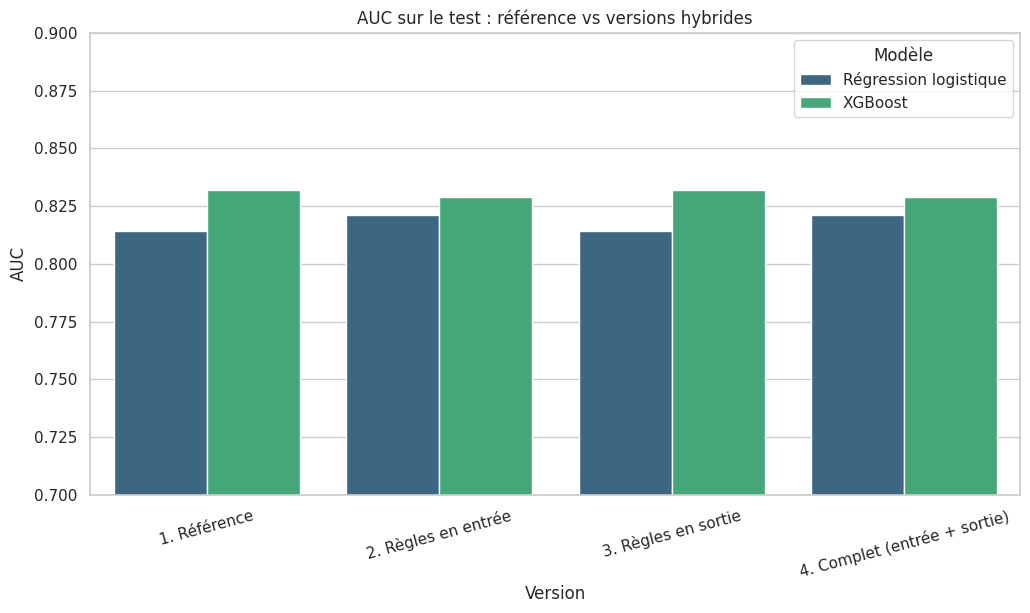

In [20]:
plt.figure(figsize=(12, 6))
sns.barplot(x="Version", y="AUC", hue="Modèle", data=df_results, palette="viridis")
plt.title("AUC sur le test : référence vs versions hybrides")
plt.ylim(0.7, 0.9)
plt.xticks(rotation=15)
plt.show()

**Conclusion de l'ablation sur le test :**
- Les versions **3 (règles en sortie)** et **1 (référence)** ont exactement les mêmes scores, pareil pour **4 (complet)**
  et **2 (règles en entrée)**. Sur ce test, la brique « règles en sortie » ne change rien : les 13 patientes R6 avaient déjà
  un risque faible, et R1 ne se déclenche jamais.
- La brique « règles en entrée » change un peu les résultats, dans un sens pour la régression logistique et dans l'autre
  pour XGBoost, mais sur 154 patientes ces écarts sont du même ordre que le bruit (voir ci-dessous).

### Ablation robuste : validation croisée répétée sur les 768 patientes

Le test ne contient que 154 patientes : les écarts du tableau ci-dessus sont trop petits pour être interprétés.
On refait donc l'ablation en **validation croisée stratifiée 5 plis × 5 répétitions** sur toutes les patientes
(prétraitement dans le `Pipeline`, donc sans fuite), avec des mesures qui **ne dépendent pas du seuil** : AUC et Brier.
Les écarts à la référence sont des **différences appariées** avec intervalle de confiance bootstrap
(1000 tirages de patientes, sur la répétition 0) ; un écart est « significatif » si l'intervalle ne contient pas 0.

In [21]:
from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn.base import clone

N_REP = 5
rskf = RepeatedStratifiedKFold(n_splits=5, n_repeats=N_REP, random_state=42)
splits = list(rskf.split(X, y))
X_all_r = ajouter_regles(X)          # les règles sont des fonctions fixes de la ligne : pas de fuite


def oof_cv(model, avec_regles):
    Xd = X_all_r if avec_regles else X
    P = np.zeros((N_REP, len(y)))
    for k, (tr, te) in enumerate(splits):
        m = creer_pipeline(clone(model), avec_regles).fit(Xd.iloc[tr], y.iloc[tr])
        P[k // 5, te] = m.predict_proba(Xd.iloc[te])[:, 1]
    return P


y_all = y.to_numpy()
rng = np.random.default_rng(42)
BOOT = rng.integers(0, len(y_all), (1000, len(y_all)))

def boot_auc(p):
    return np.array([roc_auc_score(y_all[idx], p[idx]) for idx in BOOT])

PV = {}
for name, model in models.items():
    base = oof_cv(model, False)
    ent = oof_cv(model, True)
    PV[(name, "1. Référence")] = base
    PV[(name, "2. Règles en entrée")] = ent
    PV[(name, "3. Règles en sortie")] = np.array([regles_sortie(X, base[r]) for r in range(N_REP)])
    PV[(name, "4. Complet (entrée + sortie)")] = np.array([regles_sortie(X, ent[r]) for r in range(N_REP)])

ref_auc = {n: boot_auc(PV[(n, "1. Référence")][0]) for n in models}
lignes = []
for (name, version), P in PV.items():
    auc = np.mean([roc_auc_score(y_all, P[r]) for r in range(N_REP)])
    brier = np.mean([brier_score_loss(y_all, P[r]) for r in range(N_REP)])
    d = boot_auc(P[0]) - ref_auc[name]
    lo, hi = np.percentile(d, [2.5, 97.5])
    lignes.append({"Modèle": name, "Version": version, "AUC (moy. 5 répétitions)": round(auc, 3), "Brier": round(brier, 3),
                   "ΔAUC vs référence": round(d.mean(), 4),
                   "IC95% de ΔAUC": "-" if version.startswith("1.") else f"[{lo:+.4f} ; {hi:+.4f}]",
                   "Significatif": "-" if version.startswith("1.") else ("oui" if lo > 0 or hi < 0 else "non")})
pd.DataFrame(lignes).set_index(["Modèle", "Version"])

AUC (moy. 5 répétitions)  \
Modèle                Version                                                  
Régression logistique 1. Référence                                     0.836   
                      2. Règles en entrée                              0.836   
                      3. Règles en sortie                              0.837   
                      4. Complet (entrée + sortie)                     0.836   
XGBoost               1. Référence                                     0.825   
                      2. Règles en entrée                              0.825   
                      3. Règles en sortie                              0.826   
                      4. Complet (entrée + sortie)                     0.826   

                                                    Brier  ΔAUC vs référence  \
Modèle                Version                                                  
Régression logistique 1. Référence                  0.157             0.0000   
                      2. Règles en entrée           0.156            -0.0025   
                      3. Règles en sortie           0.156             0.0013   
                      4. Complet (entrée + sortie)  0.156            -0.0024   
XGBoost               1. Référence                  0.164             0.0000   
                      2. Règles en entrée           0.164             0.0021   
                      3. Règles en sortie           0.164             0.0002   
                      4. Complet (entrée + sortie)  0.164             0.0024   

                                                          IC95% de ΔAUC  \
Modèle                Version                                             
Régression logistique 1. Référence                                    -   
                      2. Règles en entrée           [-0.0107 ; +0.0059]   
                      3. Règles en sortie           [+0.0003 ; +0.0029]   
                      4. Complet (entrée + sortie)  [-0.0107 ; +0.0059]   
XGBoost               1. Référence                                    -   
                      2. Règles en entrée           [-0.0011 ; +0.0050]   
                      3. Règles en sortie           [+0.0000 ; +0.0006]   
                      4. Complet (entrée + sortie)  [-0.0008 ; +0.0052]   

                                                   Significatif  
Modèle                Version                                    
Régression logistique 1. Référence                            -  
                      2. Règles en entrée                   non  
                      3. Règles en sortie                   oui  
                      4. Complet (entrée + sortie)          non  
XGBoost               1. Référence                            -  
                      2. Règles en entrée                   non  
                      3. Règles en sortie                   non  
                      4. Complet (entrée + sortie)          non

**Conclusion de l'ablation robuste :**
- Sur les 768 patientes (5 répétitions), l'AUC est de **0.836** pour la régression logistique et de **0.825** pour XGBoost,
  quelle que soit la version. Le Brier est quasi identique (0.156-0.157 et 0.164).
- **Règles en entrée : aucun effet démontrable.** ΔAUC = −0.0025 [−0.011 ; +0.006] pour la régression logistique et
  +0.0021 [−0.001 ; +0.005] pour XGBoost : les intervalles contiennent 0. Le signe est même **opposé** à celui du test seul
  (+0.007 et −0.003) : c'est le bruit d'un petit test. On ne peut donc affirmer ni que les règles aident la régression
  logistique, ni qu'elles gênent XGBoost.
- **Règles en sortie :** effet détectable pour la régression logistique (ΔAUC = +0.0013 [+0.0003 ; +0.0029]) mais de l'ordre du
  millième d'AUC, donc sans portée pratique. Comme R1 ne se déclenche jamais, cet effet ne peut venir que de R6, qui ramène à
  0.1 le risque des patientes sans facteur de risque. Pour XGBoost, l'écart n'est pas significatif.
- **Bilan :** les règles **ne changent pas la performance de discrimination**. Leur intérêt est ailleurs : garde-fou hors
  distribution (R1), source de chaque décision, explicabilité.
- Limites : mesures indépendantes du seuil (AUC, Brier) ; intervalles bootstrap calculés sur la répétition 0 seulement.

## 12. Cohérence avec les règles

Une question importante pour un médecin : **est-ce que le modèle respecte les règles médicales ?**
Par exemple, une patiente sans aucun facteur de risque (R6) ne devrait pas être classée « diabétique ».

On compte, parmi les patientes concernées par R6, combien sont prédites diabétiques (seuil choisi sur le train à l'étape 1) :

In [22]:
r6_test = ((X_test["Glucose"] < 140) & (X_test["BMI"] < 25) & (X_test["Age"] < 35)).values
print(f"Patientes du test concernées par R6 : {r6_test.sum()}")

for name in models:
    s = SEUILS[name]
    incoherent_ref = (proba_ref[name][r6_test] >= s).sum()
    incoherent_hyb = (proba_complet[name][r6_test] >= s).sum()
    print(f"{name} (seuil {s:.2f}) : prédites diabétiques malgré R6 -> référence = {incoherent_ref}, hybride = {incoherent_hyb}")

Patientes du test concernées par R6 : 13
Régression logistique (seuil 0.29) : prédites diabétiques malgré R6 -> référence = 0, hybride = 0
XGBoost (seuil 0.24) : prédites diabétiques malgré R6 -> référence = 0, hybride = 0


**Conclusion :** même sans règles, aucune des 13 patientes R6 n'est prédite diabétique : **0 incohérence sur 13**. Le modèle
a donc appris tout seul à respecter cette règle. Attention : avec seulement 13 patientes, un zéro est compatible avec un taux
d'incohérence réel allant jusqu'à environ 25 % (intervalle de confiance à 95 %), on ne peut donc pas parler de « 100 % de
cohérence ». La règle en sortie sert de **garantie** : si le modèle se trompe un jour sur ce type de patiente, elle le corrige.
*(À refaire sur les 768 patientes avec les prédictions hors-pli, et à étendre à R2.)*

## 13. Les jeunes malades sont-elles mieux détectées ?

À l'étape 1, on a vu que le modèle ratait beaucoup de jeunes malades (21-30 ans). On regarde si la version hybride
(règles en entrée + en sortie) fait mieux, tranche par tranche, avec les seuils choisis sur le train.

In [23]:
tranches = pd.cut(X_test["Age"], bins=[20, 30, 45, 100], labels=["21-30 ans", "31-45 ans", "46 ans et +"])

results_age_hyb = []

for name in models:
    for tranche in tranches.cat.categories:
        masque = (tranches == tranche).values
        results_age_hyb.append({
            "Modèle": name,
            "Tranche d'âge": tranche,
            "Rappel référence": recall_score(y_test[masque], proba_ref[name][masque] >= SEUILS[name]),
            "Rappel hybride": recall_score(y_test[masque], proba_complet[name][masque] >= SEUILS[name]),
        })

pd.DataFrame(results_age_hyb).round(2)

,Modèle,Tranche d'âge,Rappel référence,Rappel hybride
0,Régression logistique,21-30 ans,0.61,0.67
1,Régression logistique,31-45 ans,0.85,0.92
2,Régression logistique,46 ans et +,1.00,1.00
3,XGBoost,21-30 ans,0.67,0.61
4,XGBoost,31-45 ans,1.00,1.00
5,XGBoost,46 ans et +,1.00,1.00


**Conclusion :**
- Remarque : à l'étape 1, le rappel des jeunes était de 0.44 avec le seuil 0.5. Avec les seuils choisis sur le train il est de
  0.61 (11 sur 18) pour la régression logistique et 0.67 (12 sur 18) pour XGBoost : baisser le seuil aide déjà beaucoup les
  jeunes, mais leur rappel reste inférieur à celui des tranches plus âgées (0.85 à 1.00).
- Version hybride : régression logistique 0.61 → 0.67 (11 → 12 jeunes malades détectées), XGBoost 0.67 → 0.61 (12 → 11).
  C'est **1 patiente de différence, dans des sens opposés** : aucune conclusion possible.
- Le biais selon l'âge reste un problème, que les règles ne corrigent pas : il faudrait plus de données de jeunes malades.

## 14. Cas hors distribution : une patiente avec une glycémie de 250

Aucune patiente du jeu n'a une glycémie ≥ 200. Que fait le modèle si on lui en donne une ?

In [24]:
patiente = pd.DataFrame([{
    "Pregnancies": 1, "Glucose": 250, "BloodPressure": 70, "SkinThickness": 20, "Insulin": np.nan,
    "BMI": 23, "DiabetesPedigreeFunction": 0.3, "Age": 25,
}])

for name, model in models.items():
    pipe_ref = creer_pipeline(model).fit(X_train, y_train)
    p_ref = pipe_ref.predict_proba(patiente)[0, 1]

    pipe_r = creer_pipeline(model, avec_regles=True).fit(X_train_r, y_train)
    p_hyb = regles_sortie(patiente, pipe_r.predict_proba(ajouter_regles(patiente))[:, 1])
    src = source_decision(patiente.iloc[0])

    print(f"{name}")
    print(f"   référence : risque = {p_ref:.2f}")
    print(f"   hybride   : risque = {p_hyb[0]:.2f}  (source : {src})")

Régression logistique
   référence : risque = 0.93
   hybride   : risque = 0.96  (source : R1 : glycémie 2h >= 200 mg/dL (ADA 2024))


XGBoost
   référence : risque = 0.56
   hybride   : risque = 0.90  (source : R1 : glycémie 2h >= 200 mg/dL (ADA 2024))


**Observation :**
- **XGBoost** est un modèle à base d'arbres : il n'a jamais vu de glycémie au-dessus de 199, donc pour lui 250 c'est
  pareil que 199. Avec une patiente jeune et mince, il sous-estime le risque (0.56). La règle R1 corrige à 0.90 et donne
  la source médicale.
- **La régression logistique** donnait déjà un risque élevé (0.93) : elle « prolonge la droite » au-delà de 199, donc
  plus la glycémie monte, plus le risque monte. Ici la règle ne change presque rien, mais elle ajoute la **source**.
- C'est un des intérêts de l'approche hybride : les règles **encadrent** le modèle là où il n'a pas de données.

## 15. Calibration

Une probabilité est **calibrée** si, parmi les patientes à qui le modèle annonce 30 % de risque, environ 30 % sont réellement
diabétiques. Pour un outil qui affiche un risque à une patiente, c'est aussi important que l'AUC.

Deux outils : la **courbe de fiabilité** (fréquence observée en fonction de la probabilité prédite, idéalement sur la diagonale)
et l'**ECE** (écart moyen entre les deux, en 10 intervalles ; plus petit = mieux). On les calcule sur les prédictions **hors-pli**
des 768 patientes (5 répétitions), pas sur le petit test.

On ajoute une **recalibration par température** : on divise le logit des probabilités par un nombre T ajusté sur des prédictions
hors-pli (T > 1 = le modèle était trop sûr de lui). Pour éviter toute fuite, T est ajusté sur 4/5 des patientes et appliqué
au 1/5 restant. Elle ne change pas l'ordre des patientes (donc pas l'AUC), mais change les probabilités : **les seuils devraient
alors être re-choisis**.

ECE IC95% ECE (rép. 0)  \
Modèle                Version                                               
Régression logistique Référence                  0.036    [0.030 ; 0.073]   
                      Complet (entrée + sortie)  0.036    [0.032 ; 0.070]   
                      Référence + température    0.030    [0.029 ; 0.065]   
XGBoost               Référence                  0.061    [0.047 ; 0.093]   
                      Complet (entrée + sortie)  0.059    [0.044 ; 0.090]   
                      Référence + température    0.032    [0.029 ; 0.069]   

                                                 Brier     T  
Modèle                Version                                 
Régression logistique Référence                  0.157     -  
                      Complet (entrée + sortie)  0.156     -  
                      Référence + température    0.157  1.05  
XGBoost               Référence                  0.164     -  
                      Complet (entrée + sortie)  0.164     -  
                      Référence + température    0.161  1.47

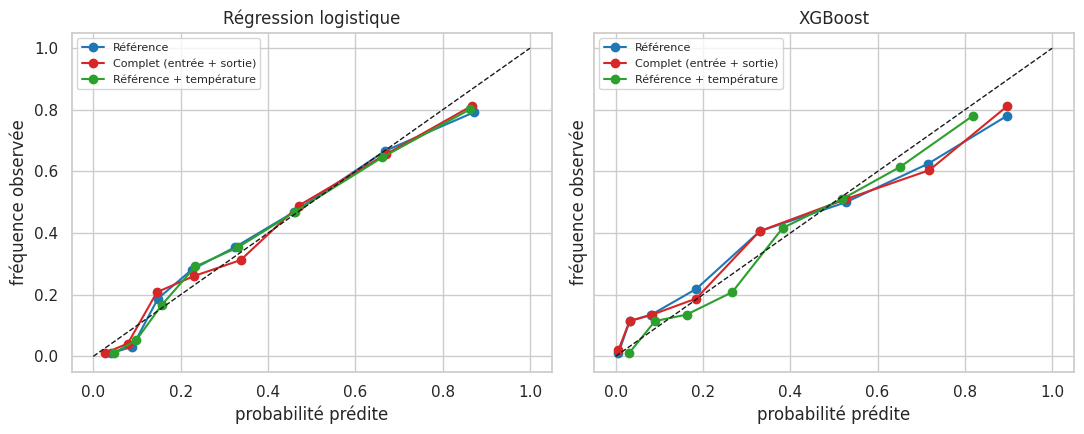

In [25]:
from scipy.optimize import minimize_scalar
from sklearn.calibration import calibration_curve
from sklearn.model_selection import StratifiedKFold


def ece_score(y_vrai, proba, n_bins=10):
    idx = np.clip(np.digitize(proba, np.linspace(0, 1, n_bins + 1)[1:-1]), 0, n_bins - 1)
    return sum((idx == b).mean() * abs(y_vrai[idx == b].mean() - proba[idx == b].mean())
               for b in range(n_bins) if (idx == b).any())


def logit(p):
    p = np.clip(p, 1e-6, 1 - 1e-6)
    return np.log(p / (1 - p))


def sigmoid(z):
    return 1 / (1 + np.exp(-z))


def ajuster_temperature(p_fit, y_fit):
    def perte(T):
        q = np.clip(sigmoid(logit(p_fit) / T), 1e-9, 1 - 1e-9)
        return -np.mean(y_fit * np.log(q) + (1 - y_fit) * np.log(1 - q))
    return minimize_scalar(perte, bounds=(0.1, 10), method="bounded").x


def recalibrer_croise(p, y_vrai, seed):
    # T ajustée sur 4/5 des prédictions hors-pli, appliquée au 1/5 restant
    sortie, Ts = np.zeros_like(p), []
    for tr, te in StratifiedKFold(5, shuffle=True, random_state=seed).split(p.reshape(-1, 1), y_vrai):
        T = ajuster_temperature(p[tr], y_vrai[tr])
        Ts.append(T)
        sortie[te] = sigmoid(logit(p[te]) / T)
    return sortie, float(np.mean(Ts))


lignes, CAL = [], {}
for name in models:
    p_ref = PV[(name, "1. Référence")]
    ref_T = np.zeros_like(p_ref)
    Ts = []
    for r in range(N_REP):
        ref_T[r], T = recalibrer_croise(p_ref[r], y_all, seed=r)
        Ts.append(T)
    variantes = {"Référence": p_ref,
                 "Complet (entrée + sortie)": PV[(name, "4. Complet (entrée + sortie)")],
                 "Référence + température": ref_T}
    for v, Pv in variantes.items():
        ece = np.mean([ece_score(y_all, Pv[r]) for r in range(N_REP)])
        brier = np.mean([brier_score_loss(y_all, Pv[r]) for r in range(N_REP)])
        boot = np.array([ece_score(y_all[idx], Pv[0][idx]) for idx in BOOT[:300]])
        lo, hi = np.percentile(boot, [2.5, 97.5])
        lignes.append({"Modèle": name, "Version": v, "ECE": round(ece, 3), "IC95% ECE (rép. 0)": f"[{lo:.3f} ; {hi:.3f}]",
                       "Brier": round(brier, 3), "T": round(np.mean(Ts), 2) if "température" in v else "-"})
        CAL[(name, v)] = Pv[0]
display(pd.DataFrame(lignes).set_index(["Modèle", "Version"]))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True)
for ax, name in zip(axes, models):
    for v, couleur in [("Référence", "tab:blue"), ("Complet (entrée + sortie)", "tab:red"), ("Référence + température", "tab:green")]:
        fy, fx = calibration_curve(y_all, CAL[(name, v)], n_bins=8, strategy="quantile")
        ax.plot(fx, fy, "o-", color=couleur, label=v)
    ax.plot([0, 1], [0, 1], "k--", lw=1)
    ax.set(title=name, xlabel="probabilité prédite", ylabel="fréquence observée")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

**Conclusion :**
- La **régression logistique est bien calibrée** : ECE 0.036, et la recalibration par température ne change presque rien (T ≈ 1.05).
  **XGBoost est un peu trop sûr de lui** : ECE 0.061 et T = 1.47. La température ramène son ECE à **0.032** et son Brier de 0.164 à 0.161,
  sans toucher à l'AUC (l'ordre des patientes ne change pas).
- **Les règles ne modifient pas la calibration** : ECE 0.036 → 0.036 (régression logistique) et 0.061 → 0.059 (XGBoost), Brier identique. Normal : elles
  ne concernent que 72 patientes sur 768 (R6), et R1 ne se déclenche jamais.
- Prudence : les intervalles de l'ECE sont larges (par exemple [0.030 ; 0.073] pour la régression logistique) et se chevauchent entre les deux modèles ;
  l'ECE est aussi biaisé vers le haut sur de petits échantillons. L'écart entre modèles est une tendance, pas une certitude ; ce qui est net, c'est que
  la température améliore XGBoost (ECE divisé par 2).
- Si on recalibre XGBoost, il faudra **re-choisir son seuil**, puisque les probabilités changent.

## 16. Cohérence avec les règles (sur les 768 patientes)

À la section 12, la cohérence n'était mesurée que sur 13 patientes du test. On la mesure ici sur **toutes** les patientes, avec les
prédictions hors-pli. Trois contrôles (aucun n'utilise l'étiquette, donc aucun risque de fuite) :
- **R6** (aucun critère de dépistage) : la patiente doit être prédite **non diabétique** ;
- **R2** (intolérance au glucose, 140-199 mg/dL, groupe à risque élevé) : la patiente doit être prédite **à risque** (≥ seuil) ;
- **Monotonie** : si on **augmente** la glycémie (+10 mg/dL) ou l'IMC (+3), le risque ne doit **pas baisser**. On compte la part de
  patientes pour lesquelles il baisse (violation). Calculé sur les 5 plis de la répétition 0, en réentraînant chaque modèle.

Les seuils sont ceux choisis sur le train (0.29 et 0.24). Intervalles de Wilson à 95 %.

In [26]:
M_R6 = ((X["Glucose"] < 140) & (X["BMI"] < 25) & (X["Age"] < 35)).to_numpy()
M_R2 = ((X["Glucose"] >= 140) & (X["Glucose"] < 200)).to_numpy()
print(f"Patientes concernées : R6 = {M_R6.sum()}, R2 = {M_R2.sum()}")

lignes = []
for (name, version), Pv in PV.items():
    seuil = SEUILS[name]
    k6 = int(((Pv[0][M_R6]) < seuil).sum())
    k2 = int(((Pv[0][M_R2]) >= seuil).sum())
    lo6, hi6 = wilson(k6, int(M_R6.sum()))
    lo2, hi2 = wilson(k2, int(M_R2.sum()))
    lignes.append({"Modèle": name, "Version": version,
                   "R6 prédites négatives": f"{np.mean([(Pv[r][M_R6] < seuil).mean() for r in range(N_REP)]):.3f}",
                   "IC95% R6": f"[{lo6:.2f} ; {hi6:.2f}]",
                   "R2 prédites à risque": f"{np.mean([(Pv[r][M_R2] >= seuil).mean() for r in range(N_REP)]):.3f}",
                   "IC95% R2": f"[{lo2:.2f} ; {hi2:.2f}]"})
display(pd.DataFrame(lignes).set_index(["Modèle", "Version"]))

Patientes concernées : R6 = 72, R2 = 197


R6 prédites négatives  \
Modèle                Version                                              
Régression logistique 1. Référence                                 0.992   
                      2. Règles en entrée                          1.000   
                      3. Règles en sortie                          1.000   
                      4. Complet (entrée + sortie)                 1.000   
XGBoost               1. Référence                                 0.994   
                      2. Règles en entrée                          0.994   
                      3. Règles en sortie                          1.000   
                      4. Complet (entrée + sortie)                 1.000   

                                                         IC95% R6  \
Modèle                Version                                       
Régression logistique 1. Référence                  [0.93 ; 1.00]   
                      2. Règles en entrée           [0.95 ; 1.00]   
                      3. Règles en sortie           [0.95 ; 1.00]   
                      4. Complet (entrée + sortie)  [0.95 ; 1.00]   
XGBoost               1. Référence                  [0.95 ; 1.00]   
                      2. Règles en entrée           [0.93 ; 1.00]   
                      3. Règles en sortie           [0.95 ; 1.00]   
                      4. Complet (entrée + sortie)  [0.95 ; 1.00]   

                                                   R2 prédites à risque  \
Modèle                Version                                             
Régression logistique 1. Référence                                0.957   
                      2. Règles en entrée                         0.940   
                      3. Règles en sortie                         0.957   
                      4. Complet (entrée + sortie)                0.940   
XGBoost               1. Référence                                0.936   
                      2. Règles en entrée                         0.937   
                      3. Règles en sortie                         0.936   
                      4. Complet (entrée + sortie)                0.937   

                                                         IC95% R2  
Modèle                Version                                      
Régression logistique 1. Référence                  [0.92 ; 0.98]  
                      2. Règles en entrée           [0.88 ; 0.96]  
                      3. Règles en sortie           [0.92 ; 0.98]  
                      4. Complet (entrée + sortie)  [0.88 ; 0.96]  
XGBoost               1. Référence                  [0.88 ; 0.95]  
                      2. Règles en entrée           [0.90 ; 0.96]  
                      3. Règles en sortie           [0.88 ; 0.95]  
                      4. Complet (entrée + sortie)  [0.90 ; 0.96]

In [27]:
def violations_monotonie(model, avec_regles, avec_sortie, perturbations):
    # perturbations : liste de (colonne, delta). Un modèle par pli (répétition 0), pas de fuite.
    viol = {col: [] for col, _ in perturbations}
    for tr, te in splits[:5]:
        Xtr = X_all_r.iloc[tr] if avec_regles else X.iloc[tr]
        m = creer_pipeline(clone(model), avec_regles).fit(Xtr, y.iloc[tr])
        Xte = X.iloc[te]
        feats = ajouter_regles if avec_regles else (lambda D: D)
        p0 = m.predict_proba(feats(Xte))[:, 1]
        if avec_sortie:
            p0 = regles_sortie(Xte, p0)
        for col, delta in perturbations:
            Xup = Xte.copy()
            Xup[col] = Xup[col] + delta
            p1 = m.predict_proba(feats(Xup))[:, 1]
            if avec_sortie:
                p1 = regles_sortie(Xup, p1)
            ok = Xte[col].notna().to_numpy()
            viol[col].append(p1[ok] < p0[ok] - 1e-9)
    return {col: np.concatenate(v) for col, v in viol.items()}


lignes = []
for name, model in models.items():
    for version, avec_r, avec_s in [("1. Référence", False, False), ("4. Complet (entrée + sortie)", True, True)]:
        v = violations_monotonie(model, avec_r, avec_s, [("Glucose", 10), ("BMI", 3)])
        lignes.append({"Modèle": name, "Version": version,
                       "Glucose +10 : risque qui baisse": f"{v['Glucose'].mean() * 100:.1f} % ({int(v['Glucose'].sum())}/{len(v['Glucose'])})",
                       "IMC +3 : risque qui baisse": f"{v['BMI'].mean() * 100:.1f} % ({int(v['BMI'].sum())}/{len(v['BMI'])})"})
display(pd.DataFrame(lignes).set_index(["Modèle", "Version"]))

Glucose +10 : risque qui baisse  \
Modèle                Version                                                        
Régression logistique 1. Référence                                   0.1 % (1/763)   
                      4. Complet (entrée + sortie)                  2.6 % (20/763)   
XGBoost               1. Référence                                20.3 % (155/763)   
                      4. Complet (entrée + sortie)                20.1 % (153/763)   

                                                   IMC +3 : risque qui baisse  
Modèle                Version                                                  
Régression logistique 1. Référence                              0.3 % (2/757)  
                      4. Complet (entrée + sortie)              0.1 % (1/757)  
XGBoost               1. Référence                           37.5 % (284/757)  
                      4. Complet (entrée + sortie)           38.4 % (291/757)

**Pour corriger la non-monotonie de XGBoost : une contrainte médicale.** On peut imposer à XGBoost que le risque ne baisse jamais quand la
glycémie ou l'IMC augmente (`monotone_constraints`). C'est une autre façon d'injecter de la connaissance (une règle sur la *forme* du modèle,
sans seuil). On vérifie le coût en performance (validation croisée 5×5, version sans règles) et le gain en cohérence.

In [28]:
# Ordre des colonnes après le prétraitement : Pregnancies, Glucose, BloodPressure, SkinThickness, Insulin, BMI, DPF, Age
modele_mono = XGBClassifier(n_estimators=300, max_depth=3, learning_rate=0.05, random_state=42,
                            monotone_constraints=(0, 1, 0, 0, 0, 1, 0, 0))
P_mono = oof_cv(modele_mono, False)
P_ref_xgb = PV[("XGBoost", "1. Référence")]
d = boot_auc(P_mono[0]) - boot_auc(P_ref_xgb[0])
lo, hi = np.percentile(d, [2.5, 97.5])
v_mono = violations_monotonie(modele_mono, False, False, [("Glucose", 10), ("BMI", 3)])
display(pd.DataFrame([
    {"Version": "XGBoost sans contrainte", "AUC (5 rép.)": round(np.mean([roc_auc_score(y_all, P_ref_xgb[r]) for r in range(N_REP)]), 3),
     "Brier": round(np.mean([brier_score_loss(y_all, P_ref_xgb[r]) for r in range(N_REP)]), 3), "ΔAUC [IC95%]": "-",
     "Glucose +10 : risque qui baisse": "20.3 %", "IMC +3 : risque qui baisse": "37.5 %"},
    {"Version": "XGBoost monotone (glycémie, IMC)", "AUC (5 rép.)": round(np.mean([roc_auc_score(y_all, P_mono[r]) for r in range(N_REP)]), 3),
     "Brier": round(np.mean([brier_score_loss(y_all, P_mono[r]) for r in range(N_REP)]), 3),
     "ΔAUC [IC95%]": f"{d.mean():+.4f} [{lo:+.4f} ; {hi:+.4f}]",
     "Glucose +10 : risque qui baisse": f"{v_mono['Glucose'].mean() * 100:.1f} %", "IMC +3 : risque qui baisse": f"{v_mono['BMI'].mean() * 100:.1f} %"},
]).set_index("Version"))

,AUC (5 rép.),Brier,ΔAUC [IC95%],Glucose +10 : risque qui baisse,IMC +3 : risque qui baisse
Version,,,,,
XGBoost sans contrainte,0.825,0.164,-,20.3 %,37.5 %
"XGBoost monotone (glycémie, IMC)",0.828,0.162,+0.0086 [+0.0018 ; +0.0161],8.9 %,10.7 %


**Conclusion :**
- **R6** (72 patientes) : sans aucune règle, 99.2 % (régression logistique) et 99.4 % (XGBoost) des patientes sont déjà prédites non diabétiques ; avec les règles,
  100 %. Sur 72 patientes, zéro incohérence reste compatible avec un taux réel allant jusqu'à environ 5 % (borne de l'intervalle de Wilson).
- **R2** (197 patientes en intolérance au glucose) : 94 à 96 % sont prédites à risque, soit environ 8 à 12 patientes classées « pas à risque » malgré R2.
  Ce n'est pas une incohérence stricte (près de 30 % des patientes en IGT du jeu ne sont pas diabétiques), mais une règle en sortie « R2 → risque au moins égal
  au seuil » est une option à discuter : elle augmenterait le rappel au prix de fausses alertes.
- **Monotonie** (+10 mg/dL de glycémie, +3 d'IMC) : la régression logistique de référence est quasi parfaite (0.1 % et 0.3 % de violations). **XGBoost ne l'est
  pas : pour 20 % des patientes le risque baisse quand la glycémie monte de 10 mg/dL, et pour 37.5 % quand l'IMC monte de 3.** C'est médicalement incohérent
  (les arbres s'ajustent au bruit).
- **Les règles en entrée dégradent la monotonie de la régression logistique** (0.1 % → 2.6 %, soit 20 cas sur 763 en glycémie). Cause très probable :
  R2 est une bande 140-199 ; une patiente à 190-199 mg/dL (18 dans le jeu) qui passe à 200 ou plus sort de la bande et perd la contribution de R2. Piste : fournir au
  modèle « glycémie ≥ 140 » (sans borne haute) et garder la bande 140-199 pour l'explication.
- **Contrainte de monotonie sur XGBoost** : imposer qu'il ne baisse jamais avec la glycémie et l'IMC réduit les violations (20 % → 9 % et 37.5 % → 10.7 %) **et améliore
  l'AUC** (0.825 → 0.828 ; ΔAUC = +0.0086 [+0.0018 ; +0.0161]). C'est l'effet le plus net sur la discrimination de toutes les briques de connaissance testées
  (les règles en entrée n'avaient aucun effet démontrable). Réserves : intervalle calculé sur une seule répétition, et plusieurs comparaisons ont été faites. Les 9-11 %
  de violations restantes viennent probablement de l'imputation KNN (les valeurs imputées dépendent des autres variables, y compris celle qu'on perturbe) : à vérifier.

## 17. Cas difficile : peu de données

Hypothèse à tester : quand il y a peu de patientes pour apprendre, les connaissances médicales (les règles) pourraient aider
davantage. On entraîne les modèles sur des **sous-échantillons stratifiés du train** de 50, 100, 200 et 400 patientes
(20 tirages chacun, plus le train complet de 614), et on évalue toujours sur le **même test** (154 patientes). Mesures indépendantes
du seuil : AUC et Brier. Les écarts « hybride moins référence » sont **appariés par tirage**.

Attention : les 20 tirages partagent le même train et le même test, la plage donnée mesure la variabilité due aux tirages, pas une
significativité statistique.

mean                              \
n                                            50     100    200    400    614   
Modèle                Version                                                  
Régression logistique 1. Référence         0.784  0.798  0.801  0.809  0.814   
                      2. Règles en entrée  0.789  0.802  0.807  0.816  0.821   
                      4. Complet           0.790  0.803  0.807  0.816  0.821   
XGBoost               1. Référence         0.734  0.773  0.796  0.805  0.832   
                      2. Règles en entrée  0.736  0.775  0.796  0.805  0.829   
                      4. Complet           0.738  0.775  0.797  0.805  0.829   

                                             std                           
n                                            50     100    200    400 614  
Modèle                Version                                              
Régression logistique 1. Référence         0.023  0.015  0.012  0.006 NaN  
                      2. Règles en entrée  0.022  0.017  0.012  0.006 NaN  
                      4. Complet           0.021  0.017  0.012  0.006 NaN  
XGBoost               1. Référence         0.044  0.027  0.021  0.020 NaN  
                      2. Règles en entrée  0.044  0.028  0.020  0.018 NaN  
                      4. Complet           0.044  0.028  0.020  0.018 NaN

ΔAUC moyen   plage 2.5-97.5 %
Modèle                n   Version                                           
Régression logistique 50  2. Règles en entrée      0.0053  [-0.009 ; +0.022]
                          4. Complet               0.0066  [-0.009 ; +0.025]
                      100 2. Règles en entrée      0.0038  [-0.007 ; +0.015]
                          4. Complet               0.0047  [-0.007 ; +0.017]
                      200 2. Règles en entrée      0.0057  [-0.003 ; +0.016]
                          4. Complet               0.0061  [-0.003 ; +0.016]
                      400 2. Règles en entrée      0.0064  [+0.000 ; +0.011]
                          4. Complet               0.0065  [+0.000 ; +0.012]
                      614 2. Règles en entrée      0.0078                  -
                          4. Complet               0.0078                  -
XGBoost               50  2. Règles en entrée      0.0016  [-0.002 ; +0.008]
                          4. Complet               0.0031  [+0.000 ; +0.009]
                      100 2. Règles en entrée      0.0020  [-0.004 ; +0.010]
                          4. Complet               0.0024  [-0.003 ; +0.010]
                      200 2. Règles en entrée      0.0002  [-0.005 ; +0.004]
                          4. Complet               0.0007  [-0.004 ; +0.006]
                      400 2. Règles en entrée     -0.0001  [-0.008 ; +0.010]
                          4. Complet              -0.0000  [-0.008 ; +0.010]
                      614 2. Règles en entrée     -0.0031                  -
                          4. Complet              -0.0031                  -

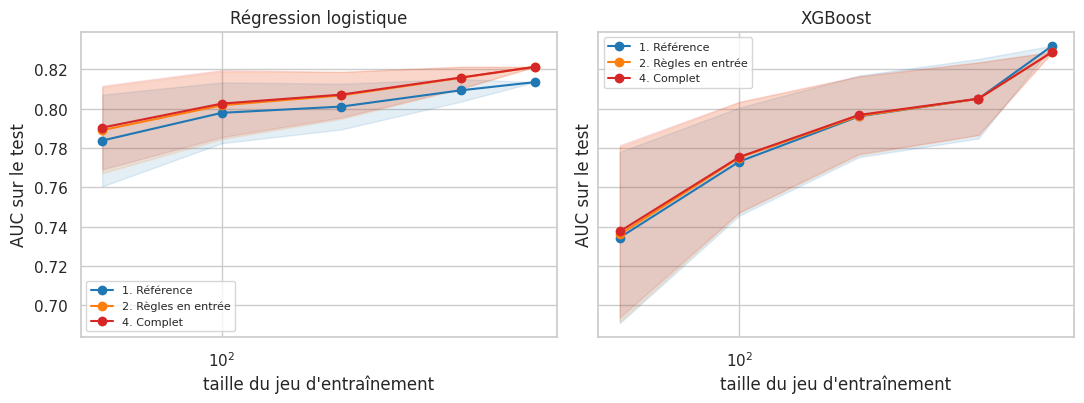

In [29]:
from sklearn.model_selection import train_test_split

TAILLES = [50, 100, 200, 400]
N_TIRAGES = 20
rng_sub = np.random.default_rng(42)
lignes = []

def evaluer_sous_echantillon(idx, n, tirage):
    Xs, ys, Xs_r = X_train.iloc[idx], y_train.iloc[idx], X_train_r.iloc[idx]
    for name, model in models.items():
        p_ref = creer_pipeline(clone(model)).fit(Xs, ys).predict_proba(X_test)[:, 1]
        p_ent = creer_pipeline(clone(model), avec_regles=True).fit(Xs_r, ys).predict_proba(X_test_r)[:, 1]
        p_comp = regles_sortie(X_test, p_ent)
        for version, p in [("1. Référence", p_ref), ("2. Règles en entrée", p_ent), ("4. Complet", p_comp)]:
            lignes.append({"n": n, "tirage": tirage, "Modèle": name, "Version": version,
                           "AUC": roc_auc_score(y_test, p), "Brier": brier_score_loss(y_test, p)})

for n in TAILLES:
    for t in range(N_TIRAGES):
        idx = train_test_split(np.arange(len(X_train)), train_size=n, stratify=y_train.to_numpy(),
                               random_state=int(rng_sub.integers(1_000_000_000)))[0]
        evaluer_sous_echantillon(idx, n, t)
evaluer_sous_echantillon(np.arange(len(X_train)), len(X_train), 0)

df_peu = pd.DataFrame(lignes)
resume = df_peu.groupby(["Modèle", "Version", "n"])["AUC"].agg(["mean", "std"]).round(3).unstack("n")
display(resume)

# écart apparié hybride - référence, par tirage
piv = df_peu.pivot_table(index=["Modèle", "n", "tirage"], columns="Version", values="AUC")
ecarts = []
for (name, n), g in piv.groupby(level=[0, 1]):
    for v in ["2. Règles en entrée", "4. Complet"]:
        d = (g[v] - g["1. Référence"]).to_numpy()
        ecarts.append({"Modèle": name, "n": n, "Version": v, "ΔAUC moyen": round(d.mean(), 4),
                       "plage 2.5-97.5 %": f"[{np.percentile(d, 2.5):+.3f} ; {np.percentile(d, 97.5):+.3f}]" if len(d) > 1 else "-"})
display(pd.DataFrame(ecarts).set_index(["Modèle", "n", "Version"]))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
for ax, name in zip(axes, models):
    for v, couleur in [("1. Référence", "tab:blue"), ("2. Règles en entrée", "tab:orange"), ("4. Complet", "tab:red")]:
        g = df_peu[(df_peu["Modèle"] == name) & (df_peu["Version"] == v)].groupby("n")["AUC"].agg(["mean", "std"]).fillna(0)
        ax.plot(g.index, g["mean"], "o-", color=couleur, label=v)
        ax.fill_between(g.index, g["mean"] - g["std"], g["mean"] + g["std"], color=couleur, alpha=0.12)
    ax.set(title=name, xlabel="taille du jeu d'entraînement", ylabel="AUC sur le test", xscale="log")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

**Conclusion :**
- **Le modèle linéaire apprend mieux avec peu de données** : à 50 patientes, AUC 0.784 pour la régression logistique contre 0.734 pour XGBoost (écart-type des tirages
  0.023 et 0.044). XGBoost ne passe devant que sur le train complet (0.832 contre 0.814 sur ce test).
- **L'hypothèse « les règles aident davantage quand les données sont rares » n'est pas confirmée.** Régression logistique : ΔAUC de +0.004 à +0.008 pour toutes
  les tailles, sans tendance (+0.005 à n = 50, +0.006 à n = 400). XGBoost : +0.002 à +0.003 à n = 50-100, 0 au-delà, −0.003 sur le train complet.
- Le petit gain constant de la régression logistique est une propriété de **ce test** (les tirages partagent le même test) : la validation croisée sur 768 patientes
  donnait −0.0025 [−0.011 ; +0.006], donc aucun gain démontré.
- Les règles en sortie ne changent presque rien (les versions « Complet » et « Règles en entrée » sont quasi identiques).

## 18. Explication pour une patiente : SHAP + règles déclenchées

Objectif de la fiche : présenter **ensemble** (1) les contributions SHAP, c'est-à-dire ce qui pousse le risque vers le haut ou vers
le bas, et (2) les règles médicales déclenchées, avec leur source.

Choix : on explique la **régression logistique avec règles en entrée + règles en sortie**, retenue pour son explicabilité
(`LinearExplainer` : exact, sans approximation). Les contributions sont en **log-odds** (échelle du modèle), relatives au risque
moyen de la population d'entraînement. Le texte destiné à la patiente est produit par **gabarit** (pas de LLM), ce qui est accepté
par la fiche si c'est justifié : le texte est déterministe, vérifiable par un médecin, et ne peut pas inventer de recommandation.

Limites : une colonne de règle est calculée à partir de la variable qu'elle découpe (corrélées), donc SHAP répartit l'effet entre les
deux et peut afficher des messages contradictoires (une règle « déclenchée » qui semble diminuer le risque). Pour l'éviter, on **regroupe
la contribution d'une règle avec celle de sa variable** (R1, R2 → glycémie ; R3 → IMC ; R4 → âge ; R5 → pression) ; R6 reste séparée.
Cet outil n'est **pas un diagnostic**.

/usr/local/lib/python3.12/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Background dataset has 614 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=614 when initializing the masker.


Fidélité SHAP (additivité) : écart maximal sur le test = 1.78e-15 log-odds


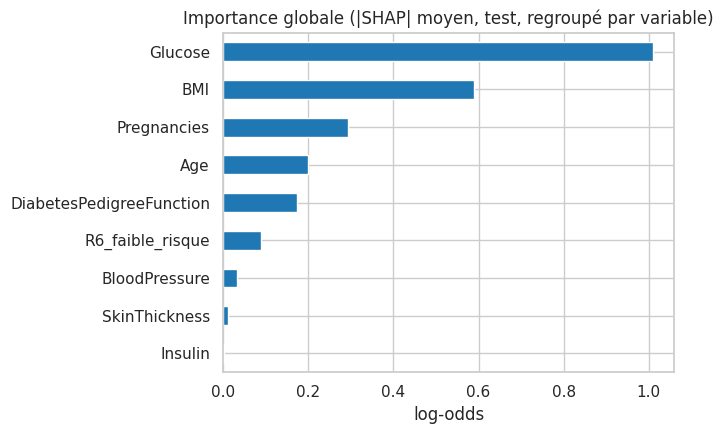

In [30]:
import shap

pipe_expl = creer_pipeline(LogisticRegression(max_iter=1000), avec_regles=True).fit(X_train_r, y_train)
pre_expl = pipe_expl.named_steps["pre"]
modele_expl = pipe_expl.named_steps["model"]
NOMS_FEAT = BASE_COLS + REGLES_COLS          # ordre des colonnes après ColumnTransformer
SEUIL_EXPL = SEUILS["Régression logistique"]

Xt_train = pre_expl.transform(X_train_r)
explainer = shap.LinearExplainer(modele_expl, Xt_train)

# Vérification de fidélité : base + somme des contributions = log-odds du modèle
Xt_test = pre_expl.transform(X_test_r)
sv_test = explainer.shap_values(Xt_test)
reconstruit = explainer.expected_value + sv_test.sum(axis=1)
ecart_max = np.abs(reconstruit - modele_expl.decision_function(Xt_test)).max()
print(f"Fidélité SHAP (additivité) : écart maximal sur le test = {ecart_max:.2e} log-odds")

# Une règle est corrélée à la variable qu'elle découpe : on regroupe sa contribution avec celle de la variable
# (R1, R2 -> glycémie ; R3 -> IMC ; R4 -> âge ; R5 -> pression). R6 reste séparée (combine glycémie, IMC et âge).
GROUPES = {"R1_diabete": "Glucose", "R2_intolerance": "Glucose", "R3_obesite": "BMI",
           "R4_depistage": "Age", "R5_hypertension": "BloodPressure"}

# Importance globale : contribution absolue moyenne sur le test
sv_groupe = pd.DataFrame(sv_test, columns=NOMS_FEAT).T.groupby(lambda n: GROUPES.get(n, n)).sum().T
imp = sv_groupe.abs().mean().sort_values()
plt.figure(figsize=(7, 4.5))
imp.plot.barh(color="tab:blue")
plt.title("Importance globale (|SHAP| moyen, test, regroupé par variable)")
plt.xlabel("log-odds")
plt.tight_layout()
plt.show()

In [31]:
UNITES = {"Glucose": "mg/dL", "BloodPressure": "mmHg (diastolique)", "SkinThickness": "mm", "Insulin": "µU/mL",
          "BMI": "kg/m²", "Age": "ans", "Pregnancies": "", "DiabetesPedigreeFunction": ""}
LIBELLES = {"Glucose": "la glycémie à 2 h", "BloodPressure": "la pression artérielle", "SkinThickness": "le pli cutané",
            "Insulin": "l'insulinémie", "BMI": "l'IMC", "Age": "l'âge", "Pregnancies": "le nombre de grossesses",
            "DiabetesPedigreeFunction": "les antécédents familiaux (score)"}
REGLES_INFO = {
    "R1_diabete": ("glycémie à 2 h ≥ 200 mg/dL (seuil de diabète)", "ADA, Standards of Care 2024, §2"),
    "R2_intolerance": ("intolérance au glucose (140-199 mg/dL)", "ADA 2024 §2 ; OMS 2006"),
    "R3_obesite": ("obésité (IMC ≥ 30)", "OMS, classification de l'IMC"),
    "R4_depistage": ("surpoids (IMC ≥ 25) et âge ≥ 35 ans : dépistage recommandé", "USPSTF 2021, JAMA 326(8):736-743"),
    "R5_hypertension": ("pression diastolique ≥ 90 mmHg", "ESC/ESH 2018 ; ADA"),
    "R6_faible_risque": ("aucun critère de dépistage rempli (règle dérivée)", "USPSTF 2021 / ADA, plafond empirique 0.1"),
}


def libelle_feature(nom, ligne, r6=True):
    if nom == "R6_faible_risque":
        return "profil sans critère de dépistage (R6)" if r6 else "absence du profil « sans critère de dépistage » (R6 non déclenchée)"
    val = ligne[nom]
    if pd.isna(val):
        return f"{LIBELLES[nom]} (valeur manquante, estimée)"
    return f"{LIBELLES[nom]} ({val:g} {UNITES[nom]})".replace(" )", ")")


def expliquer(patiente, titre="", afficher=True):
    # patiente : DataFrame d'une ligne avec les 8 variables brutes
    ligne = patiente.iloc[0]
    Xr = ajouter_regles(patiente)
    p_modele = float(pipe_expl.predict_proba(Xr)[0, 1])
    p_final = float(regles_sortie(patiente, np.array([p_modele]))[0])
    source = source_decision(ligne)
    sv = explainer.shap_values(pre_expl.transform(Xr))[0]
    contrib = pd.Series(sv, index=NOMS_FEAT).groupby(lambda n: GROUPES.get(n, n)).sum()
    contrib = contrib[contrib.abs() > 1e-6].sort_values(key=np.abs, ascending=False)
    declenchees = [r for r in REGLES_INFO if Xr[r].iloc[0] == 1]

    r6 = "R6_faible_risque" in declenchees
    haut = [libelle_feature(n, ligne, r6) for n in contrib[contrib > 0].index[:3]]
    bas = [libelle_feature(n, ligne, r6) for n in contrib[contrib < 0].index[:3]]
    decision = "AU-DESSUS du seuil de dépistage" if p_final >= SEUIL_EXPL else "en dessous du seuil de dépistage"
    texte = [f"Risque estimé : {p_final * 100:.0f} % ({decision}, seuil = {SEUIL_EXPL * 100:.0f} %)."]
    if source != "Modèle":
        if abs(p_final - p_modele) > 1e-9:
            texte.append(f"Cette valeur a été corrigée par la règle {source} (le modèle seul donnait {p_modele * 100:.0f} %).")
        else:
            texte.append(f"La règle {source} s'applique et confirme la valeur du modèle.")
    if haut:
        texte.append("Ce qui augmente le risque : " + " ; ".join(haut) + ".")
    if bas:
        texte.append("Ce qui diminue le risque : " + " ; ".join(bas) + ".")
    if declenchees:
        texte.append("Règles médicales déclenchées : " + " ; ".join(f"{r.split('_')[0]} = {REGLES_INFO[r][0]} [{REGLES_INFO[r][1]}]" for r in declenchees) + ".")
    else:
        texte.append("Aucune règle médicale déclenchée.")
    if p_final >= SEUIL_EXPL:
        texte.append("À confirmer par un examen médical (outil d'aide au dépistage, pas un diagnostic).")
    if afficher:
        print(f"\n=== {titre} ===")
        print("\n".join(texte))
    return {"p_modele": p_modele, "p_final": p_final, "source": source, "contrib": contrib, "ligne": ligne,
            "declenchees": declenchees, "texte": texte, "r6": r6}


def figure_explication(res, titre):
    c = res["contrib"].head(8)[::-1]
    etiquettes = [libelle_feature(n, res["ligne"], res["r6"]) for n in c.index]
    fig, ax = plt.subplots(figsize=(9, 4.2))
    ax.barh(range(len(c)), c.values, color=["tab:red" if v > 0 else "tab:blue" for v in c.values])
    ax.set_yticks(range(len(c)))
    ax.set_yticklabels([e if len(e) < 60 else e[:57] + "..." for e in etiquettes], fontsize=8)
    ax.axvline(0, color="k", lw=0.8)
    ax.set_xlabel("contribution au risque (log-odds) : rouge = augmente, bleu = diminue")
    regles = ", ".join(r.split("_")[0] for r in res["declenchees"]) or "aucune"
    ax.set_title(f"{titre}\nrisque {res['p_final'] * 100:.0f} %  |  décision : {res['source']}  |  règles déclenchées : {regles}", fontsize=9)
    plt.tight_layout()
    plt.show()


=== Patiente à risque élevé (test, étiquette réelle = 1) ===
Risque estimé : 99 % (AU-DESSUS du seuil de dépistage, seuil = 29 %).
Ce qui augmente le risque : la glycémie à 2 h (180 mg/dL) ; l'IMC (59.4 kg/m²) ; les antécédents familiaux (score) (2.42).
Ce qui diminue le risque : le nombre de grossesses (0) ; l'âge (25 ans) ; le pli cutané (63 mm).
Règles médicales déclenchées : R2 = intolérance au glucose (140-199 mg/dL) [ADA 2024 §2 ; OMS 2006] ; R3 = obésité (IMC ≥ 30) [OMS, classification de l'IMC].
À confirmer par un examen médical (outil d'aide au dépistage, pas un diagnostic).

=== Patiente sans critère de dépistage (R6) (étiquette réelle = 0) ===
Risque estimé : 8 % (en dessous du seuil de dépistage, seuil = 29 %).
La règle R6 : aucun critère de dépistage rempli (règle dérivée, USPSTF 2021 / ADA) s'applique et confirme la valeur du modèle.
Ce qui augmente le risque : la glycémie à 2 h (137 mg/dL) ; le pli cutané (14 mm) ; la pression artérielle (68 mmHg (diastolique)).
Ce qui 

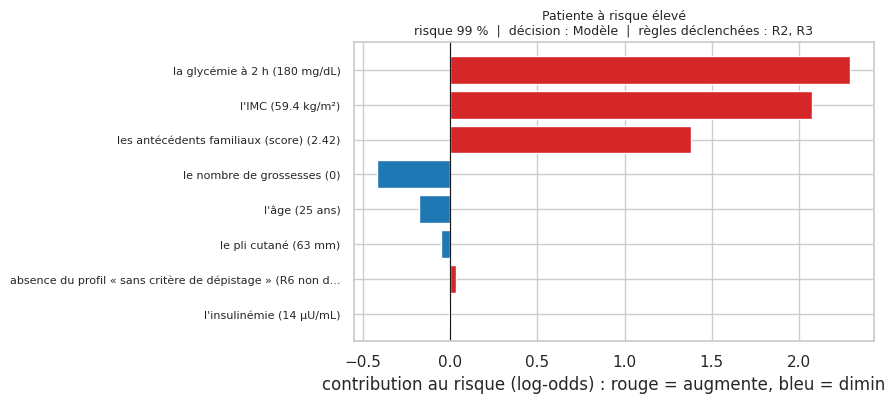

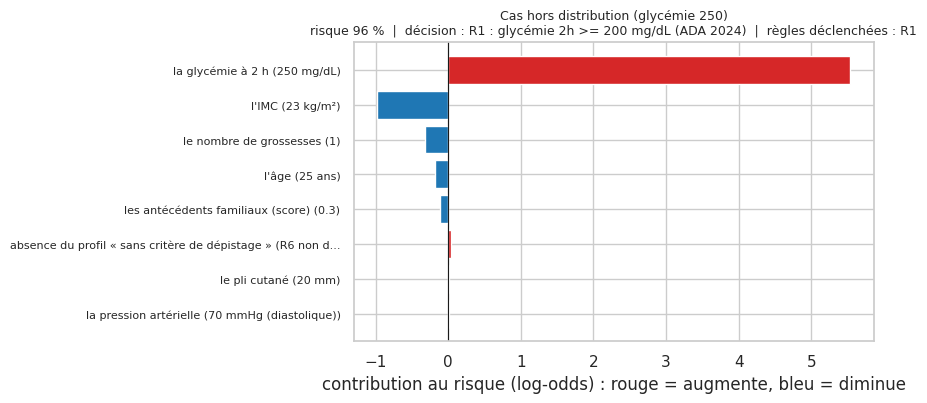

In [32]:
# Trois patientes : risque élevé, faible risque (R6) et cas hors distribution
p_test_expl = pipe_expl.predict_proba(X_test_r)[:, 1]
i_haut = int(np.argmax(p_test_expl))
masque_r6_test = (X_test["Glucose"] < 140) & (X_test["BMI"] < 25) & (X_test["Age"] < 35)
i_r6 = int(np.argmax(np.where(masque_r6_test.to_numpy(), p_test_expl, -1)))
patiente_ood = pd.DataFrame([{"Pregnancies": 1, "Glucose": 250, "BloodPressure": 70, "SkinThickness": 20, "Insulin": np.nan,
                              "BMI": 23, "DiabetesPedigreeFunction": 0.3, "Age": 25}])

res_haut = expliquer(X_test.iloc[[i_haut]], f"Patiente à risque élevé (test, étiquette réelle = {y_test.iloc[i_haut]})")
res_r6 = expliquer(X_test.iloc[[i_r6]], f"Patiente sans critère de dépistage (R6) (étiquette réelle = {y_test.iloc[i_r6]})")
res_ood = expliquer(patiente_ood, "Cas hors distribution : glycémie 250 mg/dL, 25 ans, IMC 23")
figure_explication(res_haut, "Patiente à risque élevé")
figure_explication(res_ood, "Cas hors distribution (glycémie 250)")

**Conclusion :**
- **Fidélité** : la somme « risque moyen + contributions » retrouve exactement le log-odds du modèle (écart de l'ordre de 1e-15), ce qui est attendu pour un modèle linéaire.
- Les trois patientes illustrent trois situations : (1) **risque élevé**, expliqué par la glycémie, l'IMC et les antécédents familiaux, avec les règles R2 et R3 déclenchées et leurs
  sources ; (2) **patiente R6** : la règle s'applique mais le modèle donnait déjà 8 %, le texte dit qu'elle « confirme » (il distingue « corrige » et « confirme ») ;
  (3) **cas hors distribution** (glycémie 250) : R1 s'applique ; ici la régression logistique donnait déjà 96 %, alors que XGBoost serait corrigé de 0.56 à 0.90 (section 14).
- Regrouper chaque règle avec sa variable évite les messages contradictoires (une règle « déclenchée » qui semble diminuer le risque).
- Le texte est produit par **gabarit** : déterministe et vérifiable par un médecin. Les limites sont celles du modèle : seuil de 29 %, sources de l'édition 2024, outil d'aide au dépistage et pas un diagnostic.

## 19. Analyse d'erreurs : à quelle brique attribuer chaque erreur ?

La fiche demande d'**attribuer chaque erreur à sa brique**. Méthode : on suit la prédiction à travers les étapes du pipeline
(prédictions hors-pli, seuil du modèle, moyenne sur 5 répétitions) :

1. **Référence** (imputation + modèle + seuil) → 2. **règles en entrée** (change la prédiction ?) → 3. **règles en sortie** (change la prédiction ?).

Pour chaque erreur de la version **complète** :
- si la référence avait juste mais que le passage par les **règles en entrée** a fait basculer la décision → erreur **introduite par les règles en entrée** ;
- idem pour les **règles en sortie** (en pratique R6, car R1 ne se déclenche jamais) ;
- sinon l'erreur est **héritée de la référence**, et on la rattache, dans cet ordre, à : une **donnée manquante** (glycémie ou IMC absente,
  donc imputée), au **seuil bas** (fausse alerte acceptée : probabilité entre le seuil et 0.5, que le seuil 0.5 aurait évitée), sinon au **modèle**
  (les variables ne suffisent pas à trancher).

On compte aussi les erreurs de la référence **corrigées** par chaque brique.

In [33]:
def analyse_erreurs(name):
    seuil = SEUILS[name]
    ref, ent = PV[(name, "1. Référence")], PV[(name, "2. Règles en entrée")]
    comp = PV[(name, "4. Complet (entrée + sortie)")]
    manquante = (X["Glucose"].isna() | X["BMI"].isna()).to_numpy()
    yy = y_all.astype(bool)
    comptes = []
    for r in range(N_REP):
        pr, pe, pc = ref[r] >= seuil, ent[r] >= seuil, comp[r] >= seuil
        err_ref, err_comp = pr != yy, pc != yy
        flip_A, flip_B = pr != pe, pe != pc                  # A : règles en entrée ; B : règles en sortie
        intro_A = ~err_ref & err_comp & flip_A
        intro_B = ~err_ref & err_comp & flip_B
        herite = err_ref & err_comp
        fp = herite & ~yy
        cat = {
            "Règles en entrée (introduite)": intro_A,
            "Règles en sortie (introduite)": intro_B,
            "Donnée manquante (imputation)": herite & manquante,
            "Seuil bas (fausse alerte acceptée)": fp & ~manquante & (comp[r] < 0.5),
        }
        pris = np.zeros(len(yy), bool)
        for m in cat.values():
            pris |= m
        cat["Modèle (variables insuffisantes)"] = herite & ~pris
        for k, m in cat.items():
            comptes.append({"rép": r, "Brique": k, "FN": int((m & yy).sum()), "FP": int((m & ~yy).sum())})
        comptes.append({"rép": r, "Brique": "Erreurs corrigées par les règles en entrée", "FN": int((err_ref & ~err_comp & flip_A & yy).sum()), "FP": int((err_ref & ~err_comp & flip_A & ~yy).sum())})
        comptes.append({"rép": r, "Brique": "Erreurs corrigées par les règles en sortie", "FN": int((err_ref & ~err_comp & flip_B & yy).sum()), "FP": int((err_ref & ~err_comp & flip_B & ~yy).sum())})
        comptes.append({"rép": r, "Brique": "TOTAL erreurs référence", "FN": int((err_ref & yy).sum()), "FP": int((err_ref & ~yy).sum())})
        comptes.append({"rép": r, "Brique": "TOTAL erreurs version complète", "FN": int((err_comp & yy).sum()), "FP": int((err_comp & ~yy).sum())})
    t = pd.DataFrame(comptes).groupby("Brique", sort=False)[["FN", "FP"]].mean().round(1)
    t["Total"] = t["FN"] + t["FP"]
    return t

for name in models:
    print(f"\n##### {name} (seuil {SEUILS[name]:.2f}) : nombre moyen d'erreurs par répétition, sur 768 patientes")
    display(analyse_erreurs(name))


##### Régression logistique (seuil 0.29) : nombre moyen d'erreurs par répétition, sur 768 patientes


,FN,FP,Total
Brique,,,
Règles en entrée (introduite),5.2,17.0,22.2
Règles en sortie (introduite),0.0,0.0,0.0
Donnée manquante (imputation),0.2,1.6,1.8
Seuil bas (fausse alerte acceptée),0.0,74.2,74.2
Modèle (variables insuffisantes),47.4,64.2,111.6
Erreurs corrigées par les règles en entrée,8.0,10.4,18.4
Erreurs corrigées par les règles en sortie,0.0,0.0,0.0
TOTAL erreurs référence,55.6,150.4,206.0
TOTAL erreurs version complète,52.8,157.0,209.8



##### XGBoost (seuil 0.24) : nombre moyen d'erreurs par répétition, sur 768 patientes


,FN,FP,Total
Brique,,,
Règles en entrée (introduite),2.4,5.2,7.6
Règles en sortie (introduite),0.0,0.0,0.0
Donnée manquante (imputation),0.0,1.8,1.8
Seuil bas (fausse alerte acceptée),0.0,76.6,76.6
Modèle (variables insuffisantes),37.8,87.0,124.8
Erreurs corrigées par les règles en entrée,2.2,6.2,8.4
Erreurs corrigées par les règles en sortie,0.0,0.2,0.2
TOTAL erreurs référence,40.0,171.8,211.8
TOTAL erreurs version complète,40.2,170.6,210.8


In [34]:
# Les faux négatifs les plus sévères (régression logistique, version complète, répétition 0)
name = "Régression logistique"
pc = PV[(name, "4. Complet (entrée + sortie)")][0]
fn = np.where((y_all == 1) & (pc < SEUILS[name]))[0]
pires = fn[np.argsort(pc[fn])[:8]]
Xr_all = ajouter_regles(X)
tab = X.iloc[pires][["Glucose", "BMI", "Age", "BloodPressure", "DiabetesPedigreeFunction"]].copy()
tab["risque prédit"] = pc[pires].round(2)
tab["règles déclenchées"] = [", ".join(r.split("_")[0] for r in regles if Xr_all.iloc[i][r] == 1) or "aucune" for i in pires]
print(f"{len(fn)} faux négatifs (version complète, {name}) ; les 8 pires :")
display(tab)
print("Âge médian des faux négatifs :", int(X.iloc[fn]["Age"].median()), "ans ; âge médian des malades détectées :",
      int(X.iloc[np.where((y_all == 1) & (pc >= SEUILS[name]))[0]]["Age"].median()), "ans")

52 faux négatifs (version complète, Régression logistique) ; les 8 pires :


,Glucose,BMI,Age,BloodPressure,DiabetesPedigreeFunction,risque prédit,règles déclenchées
197,107.0,22.9,23,62.0,0.678,0.03,R6
6,78.0,31.0,26,50.0,0.248,0.07,R3
218,85.0,29.0,32,74.0,1.224,0.07,aucune
284,108.0,27.0,52,80.0,0.259,0.10,R4
109,95.0,37.4,24,85.0,0.247,0.11,R3
276,106.0,26.5,29,60.0,0.296,0.11,aucune
510,84.0,29.7,46,72.0,0.297,0.12,R4
659,80.0,34.2,27,82.0,1.292,0.12,R3


Âge médian des faux négatifs : 29 ans ; âge médian des malades détectées : 37 ans


**Conclusion** (moyennes sur 5 répétitions, 768 patientes ; seuils 0.29 et 0.24) :
- La version complète fait **autant d'erreurs que la référence** : 209.8 contre 206.0 (régression logistique), 210.8 contre 211.8 (XGBoost). Les règles en entrée **introduisent** 22 erreurs
  et en **corrigent** 18 (régression logistique) ; 8 et 8 pour XGBoost : elles déplacent des patientes dans les deux sens sans bilan net, ce qui est cohérent avec l'absence d'effet démontrable.
- **Règles en sortie** : 0 erreur introduite et 0 corrigée (régression logistique), 0.2 corrigée (XGBoost). R6 ne fait pas de mal ici, mais ne sert pas non plus : le modèle classait déjà ces
  patientes négatives.
- L'essentiel des erreurs vient du **modèle** (47 faux négatifs et 64 faux positifs pour la régression logistique ; 38 et 87 pour XGBoost) et du **seuil bas**, qui produit volontairement
  74 à 77 fausses alertes (près de la moitié des faux positifs) : c'est le prix du rappel de 80 %. L'imputation n'explique qu'environ 2 erreurs (peu de valeurs manquantes sur la glycémie et l'IMC).
- Les faux négatifs les plus sévères sont pour la plupart des femmes jeunes (âge médian 29 ans contre 37 ans pour les malades détectées) avec une glycémie inférieure à 110 mg/dL et un risque
  prédit de 3 à 12 % : **aucune des 8 variables ne les distingue**. Les règles déclenchées (R3, R4) vont dans le sens d'un risque plus élevé mais ne suffisent pas. Une patiente appartient à R6
  (risque prédit 3 %) : c'est exactement le risque de fausse rassurance de cette règle, ici sans effet car le modèle la classait déjà négative. C'est un manque d'information dans les variables
  disponibles, pas un défaut de règle.

## 20. Coût de calcul

Dernière dimension de la grille : combien coûtent les briques ? On mesure le temps d'entraînement et de prédiction (sur 154 patientes) de la
référence et de la version complète. Les valeurs dépendent de la machine : seul l'ordre de grandeur compte.

In [35]:
import time

lignes = []
for name, model in models.items():
    for version, avec in [("Référence", False), ("Complet (règles entrée + sortie)", True)]:
        Xtr, Xte = (X_train_r, X_test_r) if avec else (X_train, X_test)
        t0 = time.perf_counter()
        m = creer_pipeline(clone(model), avec).fit(Xtr, y_train)
        t1 = time.perf_counter()
        p = m.predict_proba(Xte)[:, 1]
        if avec:
            p = regles_sortie(X_test, p)
        t2 = time.perf_counter()
        lignes.append({"Modèle": name, "Version": version, "Entraînement (s)": round(t1 - t0, 3),
                       "Prédiction, 154 patientes (ms)": round((t2 - t1) * 1000, 1)})
display(pd.DataFrame(lignes).set_index(["Modèle", "Version"]))

Entraînement (s)  \
Modèle                Version                                              
Régression logistique Référence                                    0.025   
                      Complet (règles entrée + sortie)             0.024   
XGBoost               Référence                                    0.094   
                      Complet (règles entrée + sortie)             0.095   

                                                        Prédiction, 154 patientes (ms)  
Modèle                Version                                                           
Régression logistique Référence                                                    9.6  
                      Complet (règles entrée + sortie)                            22.4  
XGBoost               Référence                                                   11.2  
                      Complet (règles entrée + sortie)                            23.1

## 21. Conclusion générale

**Question :** estimer le risque de diabète d'une patiente à partir de quelques mesures simples, et l'expliquer de façon vérifiable par un médecin.

| Dimension de la grille | Résultat principal | Section |
|---|---|---|
| **Performance** | AUC 0.836 (régression logistique) et 0.825 (XGBoost) en validation croisée sur 768 patientes ; **aucune version hybride démontrablement meilleure**. Au seuil choisi sur le train (rappel cible 80 %) : rappel de 0.80 (régression logistique) et 0.89 (XGBoost) sur le test. | 5, 11 |
| **Calibration** | ECE 0.036 (régression logistique), 0.061 (XGBoost) puis 0.032 après température ; les règles ne changent rien. | 15 |
| **Cohérence** | R6 : 99-100 % ; R2 : 94-96 % ; monotonie : régression logistique quasi parfaite, **XGBoost viole la monotonie pour 20 % (glycémie) et 37.5 % (IMC) des patientes**, ramenés à 9 % et 11 % par une contrainte de monotonie qui améliore aussi l'AUC (+0.009). | 12, 16 |
| **Explicabilité** | SHAP exact (régression logistique) + règles déclenchées avec source + texte par gabarit. | 18 |
| **Fidélité** | Additivité de SHAP vérifiée (écart ~1e-15). | 18 |
| **Robustesse** | Hors distribution : la règle R1 corrige XGBoost (0.56 → 0.90). Peu de données : la régression logistique est plus stable (AUC 0.784 contre 0.734 à n = 50) et les règles n'apportent pas de gain. Âge : le rappel est plus faible chez les 21-30 ans. | 13, 14, 17 |
| **Coût** | Entraînement inférieur à 0.15 s, prédiction d'environ 25 ms pour 154 patientes : le coût des règles est négligeable. | 20 |

**Ce qu'on retient**
1. **Les règles ne changent pas la discrimination** : les règles en entrée n'ont aucun effet démontrable (signes opposés entre test seul et validation croisée), les règles en sortie un effet de l'ordre de 0.001 d'AUC. L'analyse d'erreurs le confirme : les règles corrigent à peu près autant d'erreurs qu'elles en introduisent.
2. **Leur valeur est ailleurs** : garde-fou hors distribution (R1), traçabilité de chaque décision (source médicale), explication vérifiable, et contraintes de cohérence. La **contrainte de monotonie** est la brique de connaissance qui a l'effet le plus net sur la performance.
3. **Choix recommandé** : régression logistique + règles pour l'explicabilité (performance équivalente à XGBoost en validation croisée, mieux calibrée, monotone, plus stable avec peu de données) ; XGBoost sous contrainte de monotonie si l'on cherche la performance.
4. **Biais selon l'âge** : les jeunes malades sont les plus ratées (faux négatifs : âge médian 29 ans) et aucune règle ne les rattrape : il manque de l'information dans les variables.

**Limites** : jeu restreint aux femmes Pima d'au moins 21 ans (pas de généralisation) ; test de 154 patientes ; intervalles bootstrap calculés sur une seule répétition ; seuil clinique (rappel 80 %) et planchers des règles (0.9 et 0.1) sont des choix de conception ; R6 est une règle dérivée, non officielle ; sources à vérifier dans leur édition la plus récente ; hyperparamètres non optimisés ; outil d'aide au dépistage, **pas un diagnostic**.

**Pistes** : fournir au modèle « glycémie ≥ 140 » (sans borne haute) pour préserver la monotonie ; règle de sortie sur R2 ; recalibrer XGBoost puis re-choisir son seuil ; réglage d'hyperparamètres en validation croisée imbriquée ; validation sur un autre jeu de données.